# TPI · Análisis de bajas de clientes de Telco

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/julianschmidt1/tpi-analisis-de-datos/blob/feat/29-notebook-integrado/notebooks/TPI_Analisis_de_Datos.ipynb)

**Introducción al Análisis de Datos · UTN FRA · División 343**  
**Integrantes** — Matías, Julián y Emmanuel  
**Integración** — Julián, tarea 29

## Cómo ejecutarlo

En Colab, abrir el botón después de publicar la rama y elegir **Entorno de ejecución → Reiniciar sesión y ejecutar todas**. En local, instalar `requirements.txt` y ejecutar todas las celdas desde el repositorio.

Este notebook genera los archivos intermedios a partir del CSV original. Integra fundamentos y limpieza, EDA, visualización, regresión lineal, preprocesamiento y clasificación. La regresión lineal usa su propia partición. La clasificación conserva la partición estratificada del punto 21. Al integrar en main, actualizar el botón a esa rama.


## Preparación del entorno

Localizamos la raíz en local. En Colab descargamos el CSV original. Las secciones siguientes leen los archivos generados durante esta ejecución.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display

EN_COLAB_REAL = "google.colab" in sys.modules
if EN_COLAB_REAL:
    RAIZ = Path.cwd()
else:
    actual = Path.cwd().resolve()
    RAIZ = next((p for p in (actual, *actual.parents)
                 if (p / "data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv").is_file()), None)
    if RAIZ is None:
        raise FileNotFoundError("Abrí el notebook dentro del repositorio del TPI.")
ruta_raw = RAIZ / "data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
if EN_COLAB_REAL:
    ruta_raw.parent.mkdir(parents=True, exist_ok=True)
    url = "https://raw.githubusercontent.com/julianschmidt1/tpi-analisis-de-datos/main/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
    pd.read_csv(url).to_csv(ruta_raw, index=False)
print(f"Directorio de trabajo: {RAIZ}")


Directorio de trabajo: .


## Tarea 4 · Problema de negocio e hipótesis

Origen — `4_problema_hipotesis.ipynb`.

### 1. Problema de negocio

Una empresa de telecomunicaciones necesita comprender qué características están asociadas con el abandono de sus clientes (*churn*). La baja de un cliente implica dejar de percibir sus pagos futuros, por lo que identificar segmentos con mayor abandono puede ayudar a orientar las acciones de retención.

**Pregunta de negocio:** ¿cómo se relacionan la modalidad de contrato, la antigüedad y el cargo mensual con el abandono registrado en Telco Customer Churn?

**Objetivo general:** analizar los factores asociados al churn y preparar una base para construir y evaluar un modelo que clasifique clientes según su probabilidad estimada de abandono.

**Objetivos específicos:**

- Comparar las tasas de abandono entre segmentos de clientes mediante estadísticas y visualizaciones.
- Evaluar las tres hipótesis de la sección 3 con las variables disponibles.
- Aportar evidencia para priorizar segmentos donde explorar acciones de retención, como seguimiento de clientes nuevos o revisión de la oferta comercial.

Las acciones propuestas deberán evaluarse posteriormente: encontrar una asociación no demuestra que una intervención reduzca el abandono. El dataset tampoco permite calcular el retorno de una campaña sin información adicional sobre sus costos y resultados.


### 2. Unidad de análisis y variable objetivo

La **unidad de análisis** es un cliente representado por una fila del dataset. `customerID` identifica los registros y no se utilizará como predictor.

La **variable objetivo es `Churn`**, una variable cualitativa nominal binaria:

- `Yes`: el cliente tiene registrado un abandono del servicio.
- `No`: el cliente no tiene registrado un abandono del servicio.

El problema predictivo corresponde a una **clasificación supervisada binaria**, porque cada registro incluye la etiqueta que se busca predecir. Según el contrato de datos del proyecto, `Churn` se conserva como `Yes/No` durante la limpieza y el EDA; su codificación a `0/1` corresponde al preprocesamiento.

Para comparar segmentos utilizaremos la **tasa de churn**:

**Tasa de churn de un grupo (%) = 100 × cantidad de clientes con `Churn = Yes` del grupo / cantidad total de clientes del grupo.**

Cada comparación incluirá el tamaño de los grupos y sus tasas. Esto evita confundir un mayor número de bajas con una mayor proporción de abandono.


### 3. Hipótesis analíticas

Las siguientes afirmaciones son hipótesis pendientes de evaluación. Se definen los grupos y el sentido esperado de las diferencias antes de calcular sus tasas de abandono.

#### H1 · Modalidad de contrato

**Hipótesis:** los clientes con contrato mensual (`Month-to-month`) presentan una tasa de churn mayor que los clientes con contrato de un año (`One year`) y que los de dos años (`Two year`).

**Variables:** `Contract` y `Churn`.

**Cómo evaluarla:** calcular cantidad de clientes, cantidad de bajas y tasa de churn para cada categoría de `Contract`, y representarlas mediante una tabla y un gráfico de barras de tasas. La evidencia descriptiva apoyará la hipótesis si la tasa del contrato mensual supera a las otras dos; si no ocurre, la hipótesis no quedará respaldada en su formulación completa.

**Sentido de negocio:** permitiría identificar si los contratos mensuales constituyen un segmento prioritario para explorar propuestas de permanencia. No demuestra que cambiar la modalidad de contrato cause una reducción del churn.


#### H2 · Antigüedad del cliente

**Hipótesis:** los clientes con hasta 12 meses de antigüedad (`tenure <= 12`) presentan una tasa de churn mayor que los clientes con más de 12 meses (`tenure > 12`).

**Variables:** `tenure` y `Churn`.

**Cómo evaluarla:** separar los clientes en los dos grupos y comparar sus tamaños, bajas y tasas de churn. El corte en 12 meses representa el primer año de relación comercial y se fija antes de observar las tasas. Los registros con `tenure = 0` pertenecen al primer grupo si se conservan tras la limpieza. La evidencia descriptiva apoyará la hipótesis si la tasa del primer grupo es mayor.

**Sentido de negocio:** permitiría evaluar la conveniencia de investigar la experiencia de incorporación y el seguimiento durante el primer año. La comparación describe asociaciones en esta muestra; no equivale a seguir a los mismos clientes a lo largo del tiempo.


#### H3 · Cargo mensual

**Hipótesis:** los clientes cuyo cargo mensual supera la mediana de `MonthlyCharges` presentan una tasa de churn mayor que quienes tienen un cargo menor o igual a esa mediana.

**Variables:** `MonthlyCharges` y `Churn`.

**Cómo evaluarla:** calcular la mediana de `MonthlyCharges` sobre el dataset limpio, informar su valor y definir dos grupos: cargo superior a la mediana y cargo menor o igual a ella. Comparar cantidad de clientes, bajas y tasa de churn. La mediana ofrece un criterio reproducible de cargo relativamente alto dentro de la muestra, sin elegir el corte según los resultados de `Churn`. La evidencia descriptiva apoyará la hipótesis si el grupo de cargo superior a la mediana tiene una tasa mayor.

**Sentido de negocio:** permitiría señalar un segmento donde investigar la relación entre precio, servicios contratados y permanencia. Una diferencia de tasas no basta para recomendar descuentos: el cargo también puede estar asociado con el tipo de servicio o contrato.


### 4. ¿Por qué el dataset es estructurado?

El archivo original `data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv` organiza la información en una tabla de **7.043 filas y 21 columnas**, con encabezados y un esquema común para todos los registros. Cada fila representa un cliente y cada columna una característica definida.

Los campos tienen significados y dominios identificables: `tenure` representa la antigüedad en meses, `MonthlyCharges` el cargo mensual, `Contract` una categoría de contratación y `Churn` la etiqueta de abandono. Esta organización permite seleccionar columnas, filtrar registros, agrupar clientes y calcular estadísticas de forma sistemática.

Por estas razones, se trata de **datos estructurados**. La presencia de categorías guardadas como texto o de valores que requieren limpieza, como los espacios vacíos de `TotalCharges`, no cambia la estructura tabular; son cuestiones de representación y calidad que se resuelven en las tareas correspondientes.


### 5. Alcance y evaluación posterior

Las tres hipótesis pueden evaluarse con columnas presentes en el dataset. Sus resultados se calcularán durante el EDA sobre `data/processed/telco_clean.csv`; si se explora antes con `telco_provisorio.csv`, los resultados serán preliminares y deberán revisarse con la versión limpia. Esta tarea establece el problema y las hipótesis, sin anticipar hallazgos.

Las comparaciones propuestas aportan evidencia descriptiva. Se informará la diferencia entre tasas en puntos porcentuales y el tamaño de cada grupo; una diferencia observada por sí sola no demuestra significación estadística ni causalidad. Las relaciones pueden depender de otras características de los clientes.

El dataset no contiene una secuencia de observaciones fechadas que permita fijar y validar un horizonte futuro de abandono. Por ello, el modelo se evaluará como una clasificación de la etiqueta disponible. Su uso para predecir bajas futuras requeriría datos temporales y verificar que los predictores estén disponibles antes del abandono.

En las tareas de modelado se evaluará el desempeño sobre test, con exactitud, matriz de confusión y comparación con la clase mayoritaria, según el plan. Desde el negocio, los falsos negativos representan clientes que abandonan sin ser detectados y los falsos positivos representan posibles contactos de retención innecesarios.


## Tarea 5 – Relevamiento de variables: tipo teórico vs. dtype de Pandas

Origen — `5_tipos_de_variables.ipynb`.

In [2]:
import pandas as pd
df = pd.read_csv(ruta_raw)
df.shape

Out[2]: (7043, 21)


### 1. Tipos de dato que asigna Pandas por defecto

In [3]:
pd.DataFrame({"dtype": df.dtypes.astype(str), "n_unicos": df.nunique()})

Out[3]: 
                    dtype  n_unicos
customerID            str      7043
gender                str         2
SeniorCitizen       int64         2
Partner               str         2
Dependents            str         2
tenure              int64        73
PhoneService          str         2
MultipleLines         str         3
InternetService       str         3
OnlineSecurity        str         3
OnlineBackup          str         3
DeviceProtection      str         3
TechSupport           str         3
StreamingTV           str         3
StreamingMovies       str         3
Contract              str         3
PaperlessBilling      str         2
PaymentMethod         str         4
MonthlyCharges    float64      1585
TotalCharges          str      6531
Churn                 str         2


### 2. Tabla de relevamiento

| # | Variable | Tipo teórico | Subtipo | `dtype` Pandas | ¿Coincide? | Observación |
|---|---|---|---|---|---|---|
| 1 | `customerID` | Cualitativa | Nominal (identificador) | `object` | Sí | Código único por cliente (7043 valores distintos). No aporta al análisis: se descarta. |
| 2 | `gender` | Cualitativa | Nominal binaria | `object` | Sí | Female / Male. Conviene pasarla a `category`. |
| 3 | `SeniorCitizen` | Cualitativa | Nominal binaria | `int64` | **No** | Es una categoría (0 = no, 1 = sí) guardada como número. Calcular su media sería poco interpretable; hay que tratarla como categórica. |
| 4 | `Partner` | Cualitativa | Nominal binaria | `object` | Sí | Yes / No. |
| 5 | `Dependents` | Cualitativa | Nominal binaria | `object` | Sí | Yes / No. |
| 6 | `tenure` | Cuantitativa | Discreta | `int64` | Sí | Meses de antigüedad, de 0 a 72 (73 valores distintos). |
| 7 | `PhoneService` | Cualitativa | Nominal binaria | `object` | Sí | Yes / No. |
| 8 | `MultipleLines` | Cualitativa | Nominal (3 categorías) | `object` | Sí | No / Yes / "No phone service". La tercera categoría es redundante con `PhoneService = No`. |
| 9 | `InternetService` | Cualitativa | Nominal (3 categorías) | `object` | Sí | DSL / Fiber optic / No. |
| 10 | `OnlineSecurity` | Cualitativa | Nominal (3 categorías) | `object` | Sí | Yes / No / "No internet service" (redundante con `InternetService = No`). |
| 11 | `OnlineBackup` | Cualitativa | Nominal (3 categorías) | `object` | Sí | Ídem 10. |
| 12 | `DeviceProtection` | Cualitativa | Nominal (3 categorías) | `object` | Sí | Ídem 10. |
| 13 | `TechSupport` | Cualitativa | Nominal (3 categorías) | `object` | Sí | Ídem 10. |
| 14 | `StreamingTV` | Cualitativa | Nominal (3 categorías) | `object` | Sí | Ídem 10. |
| 15 | `StreamingMovies` | Cualitativa | Nominal (3 categorías) | `object` | Sí | Ídem 10. |
| 16 | `Contract` | Cualitativa | **Ordinal** | `object` | **No** | Tiene orden natural (Month-to-month < One year < Two year), pero Pandas la lee como texto sin orden. Se declara con `pd.Categorical(..., ordered=True)` o `OrdinalEncoder`. |
| 17 | `PaperlessBilling` | Cualitativa | Nominal binaria | `object` | Sí | Yes / No. |
| 18 | `PaymentMethod` | Cualitativa | Nominal (4 categorías) | `object` | Sí | Electronic check, Mailed check, Bank transfer (automatic), Credit card (automatic). |
| 19 | `MonthlyCharges` | Cuantitativa | Continua | `float64` | Sí | Cargo mensual en moneda. |
| 20 | `TotalCharges` | Cuantitativa | Continua | `object` | **No** | Es un monto, pero Pandas la lee como texto porque 11 filas contienen un espacio `" "` (todas con `tenure = 0`). Hay que convertirla con `pd.to_numeric(..., errors="coerce")` (tarea 6). |
| 21 | `Churn` | Cualitativa | Nominal binaria (**variable objetivo**) | `object` | Sí | Yes / No (26,5 % de Yes). |

> Los dtypes de la tabla son los que devuelve `pd.read_csv` por defecto; la sección 1 los verifica al ejecutar el notebook.

### 3. Resumen de discrepancias

| Variable | Pandas asigna | Debería ser | Acción (tarea que la resuelve) |
|---|---|---|---|
| `TotalCharges` | `object` | `float64` (cuantitativa continua) | Convertir con `to_numeric` y tratar los 11 vacíos (6) |
| `SeniorCitizen` | `int64` | categórica binaria | Convertir a `category` o Yes/No (7) |
| `Contract` | `object` | categórica **ordinal** | Declarar el orden o usar `OrdinalEncoder` (7 y 22) |

**Conclusión:** de las 21 variables, **18** tienen un `dtype` coherente con su naturaleza estadística y **3** requieren corrección. Además, las 16 variables categóricas que Pandas lee como texto (todas las `object` salvo `customerID` y `TotalCharges`) conviene pasarlas a `category`: ahorra memoria y deja explícito que son categóricas.

**Cantidades:** 3 cuantitativas (`tenure` discreta; `MonthlyCharges` y `TotalCharges` continuas) y 18 cualitativas (1 ordinal, 16 nominales y 1 identificador, `customerID`, que no se analiza).

## Tarea 6 · Inspección y limpieza de TotalCharges

Origen — `6_totalcharges.ipynb`.

### 1. Carga e inspección del dataset original

En Colab leemos el CSV desde GitHub. En local lo buscamos desde el directorio de ejecución y sus padres. Revisamos dimensiones, tipos, estadísticas descriptivas y duplicados para conocer el estado inicial del dataset.


In [4]:
from pathlib import Path

import pandas as pd

EN_COLAB = False

GITHUB_REPO = 'julianschmidt1/tpi-analisis-de-datos'
GITHUB_REF = 'main'
RUTA_RAW = Path('data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')
URL_RAW = f'https://raw.githubusercontent.com/{GITHUB_REPO}/{GITHUB_REF}/{RUTA_RAW.as_posix()}'

if EN_COLAB:
    RAIZ = Path.cwd()
    fuente = URL_RAW
else:
    actual = Path.cwd().resolve()
    RAIZ = next(
        (ruta for ruta in (actual, *actual.parents) if (ruta / RUTA_RAW).is_file()),
        None,
    )
    if RAIZ is None:
        raise FileNotFoundError(
            f'No se encontró {RUTA_RAW.as_posix()}. Abrí Jupyter dentro del repositorio '
            'y comprobá que esté disponible el dataset original de la tarea 2.'
        )
    fuente = RAIZ / RUTA_RAW

df = pd.read_csv(fuente)
print(f'Entorno: {"Colab" if EN_COLAB else "local"}')
print(f'Fuente: {fuente}')
print(f'Dataset original: {df.shape[0]:,} filas y {df.shape[1]} columnas.')
df.info()
print(df.describe(include="all").T.to_string())
print(f"Filas duplicadas: {df.duplicated().sum()}")
print(f"IDs de cliente repetidos: {df['customerID'].duplicated().sum()}")

Entorno: local
Fuente: .\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset original: 7,043 filas y 21 columnas.
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null

El archivo contiene 7.043 registros y 21 variables. La inspección de tipos muestra que Pandas lee `TotalCharges` como texto. Para analizar la facturación acumulada, primero hay que identificar los valores vacíos y convertir la columna a numérica.

### 2. Conversión y diagnóstico de faltantes

Quitamos espacios de los extremos, convertimos las cadenas vacías a faltantes y aplicamos `to_numeric`. La conversión genera un error si encuentra texto inesperado, para que el tratamiento de vacíos no oculte un dato inválido. Luego revisamos la antigüedad y el estado de baja de los clientes afectados.

In [5]:
total_charges = df["TotalCharges"].str.strip().replace("", pd.NA)
df["TotalCharges"] = pd.to_numeric(total_charges, errors="raise").astype("float64")

faltantes = df["TotalCharges"].isna()
print(f"TotalCharges faltantes: {faltantes.sum()} ({faltantes.mean():.2%})")
print(df.loc[faltantes, ["tenure", "Churn"]].value_counts().rename("clientes"))

TotalCharges faltantes: 11 (0.16%)
tenure  Churn
0       No       11
Name: clientes, dtype: int64


### 3. Decisión y exportación

Los 11 faltantes (0,16 % del total) corresponden a clientes con `tenure = 0` y `Churn = No`. Imputamos `0.0` porque usamos cero meses registrados como indicio de que todavía no hay cargos acumulados. Así conservamos a esos clientes en el análisis. El cero es un valor imputado a partir de la antigüedad y su validez depende de esa suposición. Solo aplicamos la regla cuando falta `TotalCharges` y la antigüedad es cero. Antes de exportar, verificamos el tipo y que no queden faltantes.

In [6]:
df.loc[faltantes & df["tenure"].eq(0), "TotalCharges"] = 0.0

assert df["TotalCharges"].dtype == "float64"
assert df["TotalCharges"].notna().all(), "Quedaron faltantes de TotalCharges por revisar."

ruta_salida = RAIZ / "data" / "processed" / "telco_step1.csv"
ruta_salida.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(ruta_salida, index=False)
print(f"Exportado: {ruta_salida.name} ({len(df)} filas)")

Exportado: telco_step1.csv (7043 filas)


## Tarea 7 · Tipos de datos y columnas calculadas

Origen — `7_tipos_columnas.ipynb`.

### 1. Carga de la salida de la tarea 6

Usamos el archivo intermedio acordado, sin repetir la limpieza de `TotalCharges` ni modificar los datos originales. Guardamos una copia para verificar al final que se mantengan las filas y las variables que no deben cambiar. El resumen de tipos permite observar qué campos Pandas interpreta como texto o números al cargar el CSV.


In [7]:
from pathlib import Path

import pandas as pd
from IPython.display import display

EN_COLAB = False

GITHUB_REPO = 'julianschmidt1/tpi-analisis-de-datos'
GITHUB_REF = 'main'
RUTA_ENTRADA = Path('data/processed/telco_step1.csv')
URL_ENTRADA = (
    f'https://raw.githubusercontent.com/{GITHUB_REPO}/'
    f'{GITHUB_REF}/{RUTA_ENTRADA.as_posix()}'
)

if EN_COLAB:
    RAIZ = Path.cwd()
    fuente = URL_ENTRADA
else:
    actual = Path.cwd().resolve()
    RAIZ = next(
        (ruta for ruta in (actual, *actual.parents) if (ruta / RUTA_ENTRADA).is_file()),
        None,
    )
    if RAIZ is None:
        raise FileNotFoundError(
            f'No se encontró {RUTA_ENTRADA.as_posix()}. '
            'Ejecutá la tarea 6 o actualizá el repositorio y abrí Jupyter dentro de él.'
        )
    fuente = RAIZ / RUTA_ENTRADA

df_step1 = pd.read_csv(fuente)
df = df_step1.copy()
assert df['TotalCharges'].dtype == 'float64'
assert df['TotalCharges'].notna().all(), 'La entrada debe cumplir la tarea 6.'

print(f'Entorno: {"Colab" if EN_COLAB else "local"}')
print(f'Fuente: {fuente}')
print(f'Entrada: {df.shape[0]:,} clientes y {df.shape[1]} columnas.')
df.info()


Entorno: local
Fuente: .\data\processed\telco_step1.csv
Entrada: 7,043 clientes y 21 columnas.
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contr

La entrada tiene 7.043 clientes y 21 columnas. `TotalCharges` ya es numérico y sus faltantes fueron tratados en la tarea 6. `SeniorCitizen` representa una condición binaria aunque se almacene como entero; las variables textuales representan categorías. Adecuar sus tipos facilita agrupar clientes sin interpretar códigos como magnitudes.


### 2. Adecuación de tipos y eliminación del identificador

Eliminamos `customerID` porque es un identificador y no una característica del servicio o comportamiento. Convertimos `SeniorCitizen` de `0/1` a `No/Yes` para expresar su naturaleza categórica y mantener una representación coherente con otros campos binarios. Verificamos el dominio antes de mapearlo para evitar generar nulos silenciosamente.

Las 17 variables categóricas, incluido `Churn`, quedan como `category`. Se conservan categorías como `No internet service` y `No phone service`, porque describen situaciones distintas de no contratar una prestación sobre un servicio disponible. `Contract` queda como categoría sin codificar: su orden y codificación se resuelven en la tarea 22.

Mantenemos los nombres originales de las columnas restantes para respetar el contrato de integración, especialmente `tenure`, `MonthlyCharges`, `TotalCharges` y `Churn`. La antigüedad se expresa como entero y los importes como `float64`.


In [8]:
assert df['SeniorCitizen'].isin([0, 1]).all(), 'SeniorCitizen tiene valores inesperados.'
df = df.drop(columns='customerID')
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

columnas_categoricas = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents',
    'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
    'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
    'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn',
]
df[columnas_categoricas] = df[columnas_categoricas].astype('category')
df = df.astype({
    'tenure': 'int64',
    'MonthlyCharges': 'float64',
    'TotalCharges': 'float64',
})

print(f'Variables categóricas: {len(columnas_categoricas)}')
print(f'Valores de SeniorCitizen: {df["SeniorCitizen"].cat.categories.tolist()}')
print(f'Valores de Churn: {df["Churn"].cat.categories.tolist()}')


Variables categóricas: 17
Valores de SeniorCitizen: ['No', 'Yes']
Valores de Churn: ['No', 'Yes']


### 3. Columnas calculadas por aritmética directa

Creamos las dos variables propuestas en el plan:

- **`ingreso_estimado = MonthlyCharges * tenure`:** aproxima el total de cargos suponiendo que el cargo mensual actual se mantuvo constante durante toda la antigüedad del cliente. Es una aproximación, no el ingreso efectivamente observado.
- **`diferencia_facturacion = TotalCharges - ingreso_estimado`:** compara el total registrado con esa aproximación. Un valor positivo indica un total registrado mayor; uno negativo indica un total menor. Puede reflejar cambios de plan, promociones u otras condiciones que el dataset no permite distinguir; por sí solo no demuestra un error de facturación.

Mostramos cinco clientes para verificar visualmente las relaciones entre las columnas de origen y las calculadas.


In [9]:
df['ingreso_estimado'] = df['MonthlyCharges'] * df['tenure']
df['diferencia_facturacion'] = df['TotalCharges'] - df['ingreso_estimado']

columnas_facturacion = [
    'tenure', 'MonthlyCharges', 'TotalCharges',
    'ingreso_estimado', 'diferencia_facturacion',
]
display(df[columnas_facturacion].head())


,tenure,MonthlyCharges,TotalCharges,ingreso_estimado,diferencia_facturacion
0,1,29.85,29.85,29.85,0.00
1,34,56.95,1889.50,1936.30,-46.80
2,2,53.85,108.15,107.70,0.45
3,45,42.30,1840.75,1903.50,-62.75
4,2,70.70,151.65,141.40,10.25


La tabla muestra que el total registrado puede diferir de mantener el cargo mensual actual durante todos los meses. Por eso, las nuevas columnas sirven para explorar la relación entre antigüedad y facturación y requieren interpretar la suposición de cargo constante.

Para los clientes de antigüedad cero cuyo `TotalCharges` se imputó a cero en la tarea 6, ambas columnas calculadas también quedan en cero. Las diferencias negativas se conservan: no son valores inválidos por definición.

Estas columnas se derivan de variables existentes y pueden ser redundantes. Para predecir `TotalCharges` en la regresión lineal no se debe usar `diferencia_facturacion`, porque contiene el propio objetivo; el plan utiliza solo `tenure` como predictor.


### 4. Verificación del esquema de salida

Definimos los tipos esperados para las 22 columnas: 17 categóricas y 5 numéricas. Comprobamos que no se hayan eliminado clientes, que no queden nulos, que `Churn` conserve las etiquetas y que las variables originales restantes mantengan sus valores. Finalmente ejecutamos `df.info()` para comprobar el criterio de terminado de la tarea.


In [10]:
tipos_esperados = {
    **dict.fromkeys(columnas_categoricas, 'category'),
    'tenure': 'int64',
    'MonthlyCharges': 'float64',
    'TotalCharges': 'float64',
    'ingreso_estimado': 'float64',
    'diferencia_facturacion': 'float64',
}
assert len(df) == len(df_step1), 'No deben eliminarse clientes en esta tarea.'
assert set(df.columns) == set(tipos_esperados), 'El esquema de columnas cambió.'
assert not df.isna().any().any(), 'La transformación no debe generar nulos.'
assert df['Churn'].isin(['Yes', 'No']).all()
assert all(str(df[columna].dtype) == tipo for columna, tipo in tipos_esperados.items())

columnas_sin_cambios = df_step1.columns.drop(['customerID', 'SeniorCitizen'])
pd.testing.assert_frame_equal(
    df[columnas_sin_cambios].astype(object),
    df_step1[columnas_sin_cambios].astype(object),
)
assert df['SeniorCitizen'].astype(object).equals(
    df_step1['SeniorCitizen'].map({0: 'No', 1: 'Yes'}).astype(object)
)

df.info()
print(f'Esquema validado: {len(df):,} clientes y {df.shape[1]} columnas.')


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   gender                  7043 non-null   category
 1   SeniorCitizen           7043 non-null   category
 2   Partner                 7043 non-null   category
 3   Dependents              7043 non-null   category
 4   tenure                  7043 non-null   int64   
 5   PhoneService            7043 non-null   category
 6   MultipleLines           7043 non-null   category
 7   InternetService         7043 non-null   category
 8   OnlineSecurity          7043 non-null   category
 9   OnlineBackup            7043 non-null   category
 10  DeviceProtection        7043 non-null   category
 11  TechSupport             7043 non-null   category
 12  StreamingTV             7043 non-null   category
 13  StreamingMovies         7043 non-null   category
 14  Contract                7043 non-nu

### 5. Exportación y recuperación de los tipos

Guardamos `data/processed/telco_step2.csv` sin índice, conservando las filas y el orden de las columnas. Esta salida permite a la tarea 9 continuar con la revisión de calidad y la decisión sobre outliers de la tarea 8.

**CSV no conserva los tipos `category`.** Para recuperarlos al continuar el análisis, se puede copiar `columnas_categoricas` y `tipos_esperados` de este notebook y cargar el archivo con `pd.read_csv(ruta, dtype=tipos_esperados)`. La siguiente celda realiza esa lectura y compara el resultado con `df` para verificar que el archivo exportado pueda reconstruirse. Usamos tolerancia numérica para las diferencias de precisión decimal propias del CSV.


In [11]:
RUTA_SALIDA = RAIZ / 'data/processed/telco_step2.csv'
RUTA_SALIDA.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(RUTA_SALIDA, index=False, encoding='utf-8')

df_recargado = pd.read_csv(RUTA_SALIDA, dtype=tipos_esperados)
pd.testing.assert_frame_equal(df, df_recargado, check_exact=False, rtol=1e-12, atol=1e-9)
print(f'Archivo generado: {RUTA_SALIDA.relative_to(RAIZ).as_posix()}')
print(f'Salida: {len(df_recargado):,} clientes y {df_recargado.shape[1]} columnas.')
print('Verificación de lectura: valores y tipos recuperados correctamente.')


Archivo generado: data/processed/telco_step2.csv
Salida: 7,043 clientes y 22 columnas.
Verificación de lectura: valores y tipos recuperados correctamente.


**Resultado de la tarea:** se conservan 7.043 clientes, se elimina `customerID`, `SeniorCitizen` queda como `No/Yes` categórico y se incorporan las dos variables de facturación. El DataFrame queda con 22 columnas y sin nulos. Los tipos categóricos se recuperan al cargar el CSV indicando el esquema. El dataset limpio final se exportará en la tarea 9.


## Tarea 8 · Detección de valores atípicos

Origen — `8_outliers.ipynb`.

### 1. Carga de los datos

Leemos la salida de la tarea 6. Buscamos el CSV en el repo cuando ejecutamos en local y usamos la URL de GitHub en Colab. Verificamos que las tres variables sean numéricas y estén completas para que los conteos consideren a todos los clientes.

In [12]:
from pathlib import Path

import pandas as pd

EN_COLAB = False

RUTA_STEP1 = Path("data/processed/telco_step1.csv")
URL_STEP1 = (
    "https://raw.githubusercontent.com/julianschmidt1/tpi-analisis-de-datos/main/"
    f"{RUTA_STEP1.as_posix()}"
)

if EN_COLAB:
    fuente = URL_STEP1
else:
    actual = Path.cwd().resolve()
    fuente = next(
        (ruta / RUTA_STEP1 for ruta in (actual, *actual.parents)
         if (ruta / RUTA_STEP1).is_file()),
        None,
    )
    if fuente is None:
        raise FileNotFoundError(f"Falta {RUTA_STEP1}. Ejecutá primero la tarea 6.")

variables = ["tenure", "MonthlyCharges", "TotalCharges"]
datos = pd.read_csv(fuente, usecols=variables)[variables]
assert all(pd.api.types.is_numeric_dtype(datos[columna]) for columna in variables)
assert datos.notna().all().all(), "Hay valores faltantes en las variables analizadas."
print(f"Clientes analizados: {len(datos):,}")

Clientes analizados: 7,043


### 2. Detección con el rango intercuartílico (IQR)

Q1 es el percentil 25 y Q3 es el percentil 75. La distancia entre ambos (IQR) mide cuánto se extiende el 50 % central de los valores. Para cada variable, marcamos como atípico un valor estrictamente menor que Q1 − 1,5 × IQR o mayor que Q3 + 1,5 × IQR.

In [13]:
from IPython.display import display

q1 = datos.quantile(0.25)
q3 = datos.quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
atipicos = datos.lt(limite_inferior) | datos.gt(limite_superior)

resumen = pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "Límite inferior": limite_inferior,
    "Límite superior": limite_superior,
    "Mínimo observado": datos.min(),
    "Máximo observado": datos.max(),
    "Valores atípicos": atipicos.sum(),
})
display(resumen.round(3))

,Q1,Q3,IQR,Límite inferior,Límite superior,Mínimo observado,Máximo observado,Valores atípicos
tenure,9.00,55.00,46.00,-60.000,124.000,0.00,72.00,0
MonthlyCharges,35.50,89.85,54.35,-46.025,171.375,18.25,118.75,0
TotalCharges,398.55,3786.60,3388.05,-4683.525,8868.675,0.00,8684.80,0


Las tres variables tienen **0 valores atípicos** según este criterio. Incluso los cargos acumulados más altos, que llegan a 8.684,80, están dentro del límite superior de 8.868,675. Los 11 ceros imputados en la tarea 6 también quedan dentro de los límites.

### 3. Boxplots

Mostramos cada variable en su propia escala. La caja va de Q1 a Q3 y la línea interior marca la mediana. Los bigotes llegan hasta los valores observados más alejados dentro de los límites del IQR. Los puntos fuera de los bigotes se mostrarían por separado.

<ipython-input-14-c6384c5c0b88>:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  eje.boxplot(datos[variable], vert=False, whis=1.5, showfliers=True)
<ipython-input-14-c6384c5c0b88>:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  eje.boxplot(datos[variable], vert=False, whis=1.5, showfliers=True)
<ipython-input-14-c6384c5c0b88>:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  eje.boxplot(datos[variable], vert=False, whis=1.5, showfliers=True)


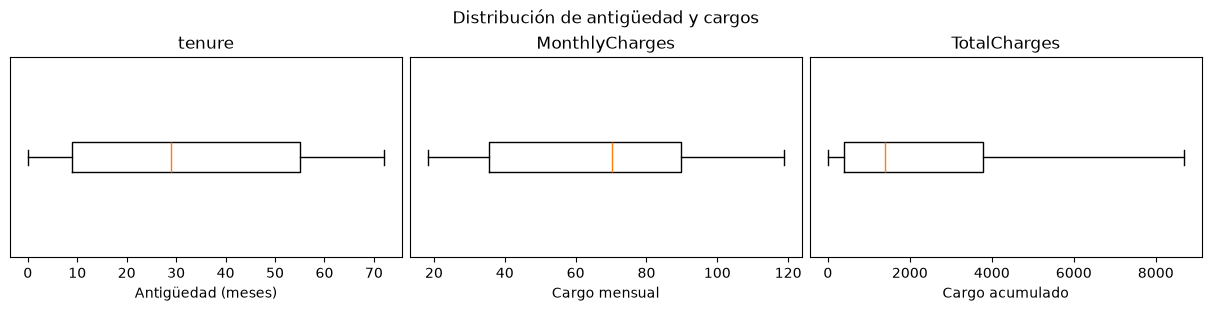

In [14]:
import matplotlib.pyplot as plt

etiquetas = ["Antigüedad (meses)", "Cargo mensual", "Cargo acumulado"]
fig, ejes = plt.subplots(1, 3, figsize=(12, 3), layout="constrained")
for eje, variable, etiqueta in zip(ejes, variables, etiquetas):
    eje.boxplot(datos[variable], vert=False, whis=1.5, showfliers=True)
    eje.set_title(variable)
    eje.set_xlabel(etiqueta)
    eje.set_yticks([])

fig.suptitle("Distribución de antigüedad y cargos")
plt.show()

Los tres gráficos muestran distribuciones sin puntos fuera de los bigotes. En `TotalCharges`, el bigote hacia los importes altos es más largo, algo compatible con que algunos clientes acumulen cargos durante más meses o paguen más por mes. La amplitud de ese tramo describe diferencias de facturación entre clientes.

### 4. Decisión para la tarea 9

**Conservar los 7.043 registros y sus valores.** El criterio de 1,5 × IQR no detectó valores atípicos en ninguna de las tres variables. Para la tarea 9 no corresponde recortar cargos ni excluir clientes por este análisis. La validez y consistencia de los datos se revisan por separado en esa tarea.

## Tarea 9 · Revisión de calidad y dataset limpio final

Origen — `9_dataset_limpio.ipynb`.

### 1. Carga de la salida de la tarea 7

Un CSV no guarda los tipos `category`, así que al leerlo indicamos el esquema acordado: 17 variables categóricas y 5 numéricas.

In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

EN_COLAB = False

GITHUB_REPO = 'julianschmidt1/tpi-analisis-de-datos'
GITHUB_REF = 'main'
RUTA_ENTRADA = Path('data/processed/telco_step2.csv')
URL_ENTRADA = (
    f'https://raw.githubusercontent.com/{GITHUB_REPO}/'
    f'{GITHUB_REF}/{RUTA_ENTRADA.as_posix()}'
)

if EN_COLAB:
    RAIZ = Path.cwd()
    fuente = URL_ENTRADA
else:
    actual = Path.cwd().resolve()
    RAIZ = next(
        (ruta for ruta in (actual, *actual.parents) if (ruta / RUTA_ENTRADA).is_file()),
        None,
    )
    if RAIZ is None:
        raise FileNotFoundError(
            f'No se encontró {RUTA_ENTRADA.as_posix()}. '
            'Actualizá el repositorio y abrí Jupyter dentro de él.'
        )
    fuente = RAIZ / RUTA_ENTRADA

columnas_categoricas = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents',
    'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
    'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
    'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn',
]
tipos_esperados = {
    **dict.fromkeys(columnas_categoricas, 'category'),
    'tenure': 'int64',
    'MonthlyCharges': 'float64',
    'TotalCharges': 'float64',
    'ingreso_estimado': 'float64',
    'diferencia_facturacion': 'float64',
}

df = pd.read_csv(fuente, dtype=tipos_esperados)

print(f'Entorno: {"Colab" if EN_COLAB else "local"}')
print(f'Fuente: {fuente}')
print(f'Entrada: {df.shape[0]:,} clientes y {df.shape[1]} columnas.')
df.info()

Entorno: local
Fuente: .\data\processed\telco_step2.csv
Entrada: 7,043 clientes y 22 columnas.
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   gender                  7043 non-null   category
 1   SeniorCitizen           7043 non-null   category
 2   Partner                 7043 non-null   category
 3   Dependents              7043 non-null   category
 4   tenure                  7043 non-null   int64   
 5   PhoneService            7043 non-null   category
 6   MultipleLines           7043 non-null   category
 7   InternetService         7043 non-null   category
 8   OnlineSecurity          7043 non-null   category
 9   OnlineBackup            7043 non-null   category
 10  DeviceProtection        7043 non-null   category
 11  TechSupport             7043 non-null   category
 12  StreamingTV             7043 non-null   category

### 2. Decisión sobre valores atípicos (tarea 8)

Un valor atípico (*outlier*) es un dato muy alejado del resto. Se detecta con el rango intercuartílico (IQR): se marca como atípico lo que queda por debajo de Q1 − 1,5 × IQR o por encima de Q3 + 1,5 × IQR. En la tarea 8 se concluyó que **no hay atípicos** y que corresponde **conservar los 7.043 registros**. Repetimos el conteo para dejar la evidencia en este notebook.

In [16]:
variables_numericas = ['tenure', 'MonthlyCharges', 'TotalCharges']
filas = []
for columna in variables_numericas:
    q1, q3 = df[columna].quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    n_atipicos = int(((df[columna] < limite_inferior) | (df[columna] > limite_superior)).sum())
    filas.append({
        'variable': columna,
        'limite_inferior': round(limite_inferior, 2),
        'limite_superior': round(limite_superior, 2),
        'atipicos': n_atipicos,
    })

resumen_atipicos = pd.DataFrame(filas).set_index('variable')
display(resumen_atipicos)
assert resumen_atipicos['atipicos'].sum() == 0, 'Hay atípicos: revisar la decisión de la tarea 8.'
print('Decisión aplicada: se conservan todos los registros (0 valores atípicos).')

Decisión aplicada: se conservan todos los registros (0 valores atípicos).


,limite_inferior,limite_superior,atipicos
variable,,,
tenure,-60.00,124.00,0
MonthlyCharges,-46.02,171.38,0
TotalCharges,-4683.52,8868.67,0


### 3. Revisión de calidad de datos

En la Clase 1 se vieron las dimensiones de la calidad del dato. Revisamos cuatro:

- **Completitud:** que no falten datos.
- **Validez:** que cada valor esté dentro de lo permitido (por ejemplo, `Churn` solo puede ser `Yes` o `No`).
- **Unicidad:** que no haya registros repetidos por error.
- **Consistencia:** que las variables no se contradigan entre sí (por ejemplo, un cliente sin servicio de internet no puede tener soporte técnico contratado).

In [17]:
servicios_internet = [
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
]
binarias = [
    'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
    'PaperlessBilling', 'Churn',
]

controles = []


def registrar(dimension, control, cumple):
    controles.append({'dimension': dimension, 'control': control, 'resultado': 'OK' if cumple else 'FALLA'})


# Completitud
registrar('Completitud', 'No hay valores nulos en ninguna columna', not df.isna().any().any())
registrar('Completitud', 'Se mantienen 7.043 clientes y 22 columnas', df.shape == (7043, 22))

# Validez
registrar('Validez', 'Variables binarias solo toman Yes o No', all(df[c].isin(['Yes', 'No']).all() for c in binarias))
registrar('Validez', 'gender solo toma Female o Male', df['gender'].isin(['Female', 'Male']).all())
registrar('Validez', 'Contract tiene las 3 categorías esperadas', set(df['Contract'].unique()) == {'Month-to-month', 'One year', 'Two year'})
registrar('Validez', 'tenure está entre 0 y 72 meses', df['tenure'].between(0, 72).all())
registrar('Validez', 'MonthlyCharges es positivo', (df['MonthlyCharges'] > 0).all())
registrar('Validez', 'TotalCharges no es negativo', (df['TotalCharges'] >= 0).all())

# Consistencia
registrar('Consistencia', 'Sin servicio telefónico, MultipleLines es "No phone service"',
          (df.loc[df['PhoneService'] == 'No', 'MultipleLines'] == 'No phone service').all())
registrar('Consistencia', 'Con servicio telefónico, MultipleLines no es "No phone service"',
          (df.loc[df['PhoneService'] == 'Yes', 'MultipleLines'] != 'No phone service').all())
registrar('Consistencia', 'Sin internet, los 6 servicios de internet son "No internet service"',
          (df.loc[df['InternetService'] == 'No', servicios_internet] == 'No internet service').all().all())
registrar('Consistencia', 'Con internet, ningún servicio es "No internet service"',
          (df.loc[df['InternetService'] != 'No', servicios_internet] != 'No internet service').all().all())
registrar('Consistencia', 'Clientes con tenure = 0 tienen TotalCharges = 0',
          (df.loc[df['tenure'] == 0, 'TotalCharges'] == 0).all())
registrar('Consistencia', 'Clientes con tenure > 0 tienen TotalCharges > 0',
          (df.loc[df['tenure'] > 0, 'TotalCharges'] > 0).all())
registrar('Consistencia', 'ingreso_estimado = MonthlyCharges × tenure',
          np.allclose(df['ingreso_estimado'], df['MonthlyCharges'] * df['tenure']))
registrar('Consistencia', 'diferencia_facturacion = TotalCharges − ingreso_estimado',
          np.allclose(df['diferencia_facturacion'], df['TotalCharges'] - df['ingreso_estimado']))

tabla_controles = pd.DataFrame(controles)
display(tabla_controles)
assert (tabla_controles['resultado'] == 'OK').all(), 'Hay controles de calidad que fallan.'
print(f'{len(tabla_controles)} controles de calidad superados.')

16 controles de calidad superados.


,dimension,control,resultado
0,Completitud,No hay valores nulos en ninguna columna,OK
1,Completitud,Se mantienen 7.043 clientes y 22 columnas,OK
2,Validez,Variables binarias solo toman Yes o No,OK
3,Validez,gender solo toma Female o Male,OK
4,Validez,Contract tiene las 3 categorías esperadas,OK
5,Validez,tenure está entre 0 y 72 meses,OK
6,Validez,MonthlyCharges es positivo,OK
7,Validez,TotalCharges no es negativo,OK
8,Consistencia,"Sin servicio telefónico, MultipleLines es ""No ...",OK
9,Consistencia,"Con servicio telefónico, MultipleLines no es ""...",OK


#### Unicidad: filas repetidas

Una fila repetida podría ser un cliente cargado dos veces. Revisamos cuántas hay.

In [18]:
n_duplicadas = int(df.duplicated().sum())
print(f'Filas idénticas (sin contar la primera aparición): {n_duplicadas}')
display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6))

Filas idénticas (sin contar la primera aparición): 22


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ingreso_estimado,diferencia_facturacion
6491,Female,No,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.20,69.20,Yes,69.20,0.0
6764,Female,No,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.20,69.20,Yes,69.20,0.0
4495,Female,No,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.10,70.10,Yes,70.10,0.0
6267,Female,No,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.10,70.10,Yes,70.10,0.0
5522,Female,No,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,70.15,70.15,Yes,70.15,0.0
5759,Female,No,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,70.15,70.15,Yes,70.15,0.0


Hay filas idénticas porque eliminamos `customerID` en la tarea 7. En el dataset original los 7.043 identificadores eran distintos, es decir, **cada fila es un cliente diferente** que casualmente tiene el mismo perfil que otro (mismos servicios, misma antigüedad y mismos cargos). No son errores de carga. **Decisión: conservarlas**, porque eliminarlas haría perder clientes reales y alteraría las proporciones de `Churn`.

### 4. Exportación del dataset limpio

Guardamos `data/processed/telco_clean.csv` sin índice y comprobamos que, al volver a leerlo con el esquema, se recupera exactamente el mismo DataFrame.

In [19]:
RUTA_SALIDA = RAIZ / 'data/processed/telco_clean.csv'
RUTA_SALIDA.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(RUTA_SALIDA, index=False, encoding='utf-8')

df_recargado = pd.read_csv(RUTA_SALIDA, dtype=tipos_esperados)
pd.testing.assert_frame_equal(df, df_recargado, check_exact=False, rtol=1e-12, atol=1e-9)

print(f'Archivo generado: {RUTA_SALIDA.relative_to(RAIZ).as_posix()}')
print(f'Salida: {len(df_recargado):,} clientes y {df_recargado.shape[1]} columnas, sin nulos.')
print('Verificación de lectura: valores y tipos recuperados correctamente.')

Archivo generado: data/processed/telco_clean.csv
Salida: 7,043 clientes y 22 columnas, sin nulos.
Verificación de lectura: valores y tipos recuperados correctamente.


**Resultado de la tarea:** el dataset limpio final tiene **7.043 clientes y 22 columnas** (17 categóricas y 5 numéricas), sin valores nulos y sin valores atípicos. Se conservaron todos los registros, incluidas las 22 filas de perfil repetido, que corresponden a clientes distintos. Los 16 controles de completitud, validez y consistencia se cumplen. El archivo `data/processed/telco_clean.csv` queda como entrada de las tareas 10 en adelante (EDA, visualización, preprocesamiento y modelado).

**Recordatorio de uso:** al leerlo, indicar el esquema con `pd.read_csv('data/processed/telco_clean.csv', dtype=tipos_esperados)` para recuperar los tipos `category`.

## Tarea 10 · Estadística descriptiva de antigüedad y cargos

Origen — `10_estadistica_descriptiva.ipynb`.

### 1. Carga del dataset

Leemos el dataset limpio generado en la sección 9.

In [20]:
from pathlib import Path
from urllib.error import HTTPError

import pandas as pd

EN_COLAB = False

variables = ["tenure", "MonthlyCharges", "TotalCharges"]
ruta_limpia = Path("data/processed/telco_clean.csv")
ruta_provisoria = Path("data/processed/telco_provisorio.csv")

if EN_COLAB:
    url_repo = "https://raw.githubusercontent.com/julianschmidt1/tpi-analisis-de-datos/main/"
    fuente = url_repo + ruta_limpia.as_posix()
    try:
        datos = pd.read_csv(fuente, usecols=variables)
    except HTTPError as error:
        if error.code != 404:
            raise
        fuente = url_repo + ruta_provisoria.as_posix()
        datos = pd.read_csv(fuente, usecols=variables)
else:
    actual = Path.cwd().resolve()
    raiz = next(
        (ruta for ruta in (actual, *actual.parents)
         if (ruta / ruta_limpia).is_file() or (ruta / ruta_provisoria).is_file()),
        None,
    )
    if raiz is None:
        raise FileNotFoundError("Falta el CSV de la tarea 3 o el dataset limpio de la tarea 9.")
    fuente = raiz / ruta_limpia
    if not fuente.is_file():
        fuente = raiz / ruta_provisoria
    datos = pd.read_csv(fuente, usecols=variables)

datos = datos[variables]
print(f"Fuente: {fuente}")

Fuente: .\data\processed\telco_clean.csv


### 2. Cálculo de las estadísticas

La media es el promedio, la mediana divide los valores ordenados en dos mitades y la moda es el valor más frecuente. Si hay un empate, mostramos todas las modas. El desvío estándar muestral y el rango describen la dispersión. El rango intercuartílico (IQR = Q3 − Q1) mide cuánto abarca el 50 % central de los datos.

La asimetría indica hacia qué lado se extiende más la distribución. Para la curtosis usamos el exceso de Fisher, que toma el valor 0 como referencia para una distribución normal.

In [21]:
resumen = datos.agg(["count", "mean", "median", "std", "skew", "kurt"]).T.rename(columns={
    "count": "Datos válidos",
    "mean": "Media",
    "median": "Mediana",
    "std": "Desvío estándar",
    "skew": "Asimetría",
    "kurt": "Exceso de curtosis",
})
resumen["Datos válidos"] = resumen["Datos válidos"].astype(int)
resumen["Faltantes"] = datos.isna().sum()
resumen["Moda"] = [", ".join(map(str, datos[columna].mode())) for columna in variables]
resumen["Rango"] = datos.max() - datos.min()
resumen["IQR"] = datos.quantile(0.75) - datos.quantile(0.25)

resumen = resumen[[
    "Datos válidos", "Faltantes", "Media", "Mediana", "Moda",
    "Desvío estándar", "Rango", "IQR", "Asimetría", "Exceso de curtosis",
]]
resumen.round(2)

Out[21]: 
                Datos válidos  Faltantes  ...  Asimetría  Exceso de curtosis
tenure                   7043          0  ...       0.24               -1.39
MonthlyCharges           7043          0  ...      -0.22               -1.26
TotalCharges             7043          0  ...       0.96               -0.23

[3 rows x 10 columns]


### 3. Interpretación de la versión limpia

- **Antigüedad (`tenure`).** La mediana es de 29 meses y la media de 32,37. La moda es 1 mes, mientras que el 50 % central abarca 46 meses. Esto muestra que conviven clientes recién incorporados y clientes con bastante antigüedad. Conviene distinguir estos grupos al estudiar la permanencia.
- **Cargo mensual (`MonthlyCharges`).** La mediana es de 70,35 y el promedio de 64,76. La asimetría es levemente negativa y la moda es 20,05. El IQR de 54,35 muestra diferencias relevantes entre los cargos que paga el grueso de la cartera.
- **Cargo acumulado (`TotalCharges`).** La media de 2.279,73 supera la mediana de 1.394,55 y la asimetría es positiva (0,96). Los importes altos elevan el promedio, por lo que la mediana ayuda a describir el cargo acumulado de un cliente típico. Este cálculo usa los 7.043 clientes después de la imputación justificada en la limpieza.



## Tarea 11 · Correlaciones de Pearson y Spearman

Origen — `11_correlaciones.ipynb`.

### 1. Carga del dataset

Leemos el dataset limpio generado en la sección 9.

In [22]:
from pathlib import Path
from urllib.error import HTTPError

import pandas as pd

EN_COLAB = False

variables = ["tenure", "MonthlyCharges", "TotalCharges"]
ruta_limpia = Path("data/processed/telco_clean.csv")
ruta_provisoria = Path("data/processed/telco_provisorio.csv")

if EN_COLAB:
    url_repo = "https://raw.githubusercontent.com/julianschmidt1/tpi-analisis-de-datos/main/"
    fuente = url_repo + ruta_limpia.as_posix()
    try:
        datos = pd.read_csv(fuente, usecols=variables)
    except HTTPError as error:
        if error.code != 404:
            raise
        fuente = url_repo + ruta_provisoria.as_posix()
        datos = pd.read_csv(fuente, usecols=variables)
else:
    actual = Path.cwd().resolve()
    raiz = next(
        (ruta for ruta in (actual, *actual.parents)
         if (ruta / ruta_limpia).is_file() or (ruta / ruta_provisoria).is_file()),
        None,
    )
    if raiz is None:
        raise FileNotFoundError("Falta el CSV de la tarea 3 o el dataset limpio de la tarea 9.")
    fuente = raiz / ruta_limpia
    if not fuente.is_file():
        fuente = raiz / ruta_provisoria
    datos = pd.read_csv(fuente, usecols=variables)

datos = datos[variables]
print(f"Fuente: {fuente}")

Fuente: .\data\processed\telco_clean.csv


### 2. Correlación de Pearson

Pearson mide qué tan cerca está la relación entre dos variables de seguir una línea recta. El coeficiente va de −1 a +1. Un signo positivo indica que los valores altos de una variable tienden a aparecer junto con valores altos de la otra. Calculamos la matriz y contamos cuántas filas se usaron en cada comparación.

In [23]:
pearson = datos.corr(method="pearson")
presentes = datos.notna().astype(int)
pares_validos = presentes.T @ presentes

print("Correlación de Pearson")
print(pearson.round(3).to_string())
print("\nFilas disponibles por par de variables")
print(pares_validos.to_string())

Correlación de Pearson
                tenure  MonthlyCharges  TotalCharges
tenure           1.000           0.248         0.826
MonthlyCharges   0.248           1.000         0.651
TotalCharges     0.826           0.651         1.000

Filas disponibles por par de variables
                tenure  MonthlyCharges  TotalCharges
tenure            7043            7043          7043
MonthlyCharges    7043            7043          7043
TotalCharges      7043            7043          7043


Con el CSV limpio, la asociación lineal más alta es la de antigüedad y cargo acumulado (0,826). Los clientes con más meses de servicio tienden a haber acumulado más cargos. Las tres comparaciones usan los 7.043 clientes del dataset limpio.

### 3. Correlación de Spearman

Spearman trabaja con los rangos de los valores. Mide si, al ordenar a los clientes por una variable, la otra tiende a subir o bajar en el mismo orden, incluso si la relación forma una curva. Usamos las mismas tres columnas para comparar las dos matrices.

In [24]:
spearman = datos.corr(method="spearman")
print("Correlación de Spearman")
print(spearman.round(3).to_string())

Correlación de Spearman
                tenure  MonthlyCharges  TotalCharges
tenure           1.000           0.276         0.890
MonthlyCharges   0.276           1.000         0.638
TotalCharges     0.890           0.638         1.000


### 4. Comparación e interpretación

- **Antigüedad y cargo acumulado.** Pearson da 0,826 y Spearman da 0,890. Los clientes con mayor antigüedad suelen ocupar posiciones más altas en el cargo acumulado. La correlación es más alta al comparar el orden que al ajustar la relación a una línea recta.
- **Cargo mensual y cargo acumulado.** Pearson da 0,651 y Spearman da 0,638. Los clientes con cargos mensuales más altos tienden a acumular más cargos, aunque el total también varía con los meses de servicio.
- **Antigüedad y cargo mensual.** Pearson da 0,248 y Spearman da 0,276. Es la asociación positiva más débil. Saber cuántos meses lleva un cliente da poca información sobre cuánto paga por mes.



## Tarea 12 · Análisis categórico de la baja de clientes

Origen — `12_analisis_categorico.ipynb`.

### 1. Carga del dataset

Leemos el dataset limpio generado durante esta ejecución.

In [25]:
from pathlib import Path
from urllib.error import HTTPError

import pandas as pd

EN_COLAB = False

sociodemograficas = ["gender", "SeniorCitizen", "Partner", "Dependents"]
contratacion = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling"]
variables = sociodemograficas + contratacion + ["Churn"]
ruta_limpia = Path("data/processed/telco_clean.csv")
ruta_provisoria = Path("data/processed/telco_provisorio.csv")

if EN_COLAB:
    url_repo = "https://raw.githubusercontent.com/julianschmidt1/tpi-analisis-de-datos/main/"
    fuente = url_repo + ruta_limpia.as_posix()
    try:
        datos = pd.read_csv(fuente, usecols=variables)
    except HTTPError as error:
        if error.code != 404:
            raise
        fuente = url_repo + ruta_provisoria.as_posix()
        datos = pd.read_csv(fuente, usecols=variables)
else:
    actual = Path.cwd().resolve()
    raiz = next(
        (ruta for ruta in (actual, *actual.parents)
         if (ruta / ruta_limpia).is_file() or (ruta / ruta_provisoria).is_file()),
        None,
    )
    if raiz is None:
        raise FileNotFoundError("Falta el CSV de la tarea 3 o el dataset limpio de la tarea 9.")
    fuente = raiz / ruta_limpia
    if not fuente.is_file():
        fuente = raiz / ruta_provisoria
    datos = pd.read_csv(fuente, usecols=variables)

datos = datos[variables]
print(f"Fuente: {fuente}")

Fuente: .\data\processed\telco_clean.csv


### 2. Frecuencias y tasas de baja por grupo

La frecuencia absoluta cuenta clientes por categoría. La frecuencia relativa divide ese conteo por el total de la cartera. Con `crosstab(normalize="index")` dividimos por el total de cada grupo. Así, el porcentaje de baja responde, por ejemplo, cuántos de cada 100 clientes con contrato mensual se dieron de baja. Incluimos el conteo para ver el tamaño de cada grupo antes de comparar porcentajes.

In [26]:
assert datos["Churn"].isin(["Yes", "No"]).all(), "Churn debe contener Yes o No."

tablas = {}
for variable in sociodemograficas + contratacion:
    grupos = datos[variable].astype("string").fillna("Sin dato")
    conteos = pd.crosstab(grupos, datos["Churn"]).reindex(columns=["No", "Yes"], fill_value=0)
    porcentajes = pd.crosstab(grupos, datos["Churn"], normalize="index").reindex(
        columns=["No", "Yes"], fill_value=0
    ) * 100
    clientes = conteos.sum(axis=1)
    tablas[variable] = pd.DataFrame({
        "Clientes": clientes,
        "% de la cartera": 100 * clientes / len(datos),
        "Bajas": conteos["Yes"],
        "% sigue activo": porcentajes["No"],
        "% se dio de baja": porcentajes["Yes"],
    })

for nombre, columnas in [("Sociodemográficas", sociodemograficas), ("Contratación y servicio", contratacion)]:
    print(nombre)
    print(pd.concat({columna: tablas[columna] for columna in columnas}).round(2).to_string())
    print()

Sociodemográficas
                      Clientes  % de la cartera  Bajas  % sigue activo  % se dio de baja
gender        Female      3488            49.52    939           73.08             26.92
              Male        3555            50.48    930           73.84             26.16
SeniorCitizen No          5901            83.79   1393           76.39             23.61
              Yes         1142            16.21    476           58.32             41.68
Partner       No          3641            51.70   1200           67.04             32.96
              Yes         3402            48.30    669           80.34             19.66
Dependents    No          4933            70.04   1543           68.72             31.28
              Yes         2110            29.96    326           84.55             15.45

Contratación y servicio
                                            Clientes  % de la cartera  Bajas  % sigue activo  % se dio de baja
Contract         Month-to-month              

### 3. Hallazgos con el CSV limpio

1. **Contrato.** Se dio de baja el 42,71 % de los clientes con contrato mensual, frente al 11,27 % de los clientes con contrato anual y el 2,83 % de quienes tenían contrato de dos años. El grupo mensual concentra la mayor tasa de baja entre los tipos de contrato.
2. **Adultos mayores.** La tasa fue del 41,68 % para `SeniorCitizen = 1` frente al 23,61 % para `SeniorCitizen = 0`. La diferencia sirve para identificar un grupo a estudiar con más detalle y cruzarlo con el tipo de contrato.
3. **Servicio de internet.** Los clientes con fibra óptica tuvieron una tasa de baja del 41,89 %, frente al 18,96 % en DSL y al 7,40 % entre quienes no tenían internet contratado. La comparación permite identificar el segmento de servicio con mayor tasa observada.

Estas comparaciones describen asociaciones entre categorías y bajas. Para el análisis final, revisar las cifras después de ejecutar el notebook con `telco_clean.csv`.

## Tarea 13 · Filtrado avanzado de clientes

Origen — `13_filtrado_avanzado.ipynb`.

### 1. Carga del dataset

Leemos el dataset limpio generado durante esta ejecución.

In [27]:
from pathlib import Path
from urllib.error import HTTPError

import pandas as pd

EN_COLAB = False

variables = ["Contract", "InternetService", "MonthlyCharges", "tenure", "PaymentMethod", "Churn"]
ruta_limpia = Path("data/processed/telco_clean.csv")
ruta_provisoria = Path("data/processed/telco_provisorio.csv")

if EN_COLAB:
    url_repo = "https://raw.githubusercontent.com/julianschmidt1/tpi-analisis-de-datos/main/"
    fuente = url_repo + ruta_limpia.as_posix()
    try:
        datos = pd.read_csv(fuente, usecols=variables)
    except HTTPError as error:
        if error.code != 404:
            raise
        fuente = url_repo + ruta_provisoria.as_posix()
        datos = pd.read_csv(fuente, usecols=variables)
else:
    actual = Path.cwd().resolve()
    raiz = next(
        (ruta for ruta in (actual, *actual.parents)
         if (ruta / ruta_limpia).is_file() or (ruta / ruta_provisoria).is_file()),
        None,
    )
    if raiz is None:
        raise FileNotFoundError("Falta el CSV de la tarea 3 o el dataset limpio de la tarea 9.")
    fuente = raiz / ruta_limpia
    if not fuente.is_file():
        fuente = raiz / ruta_provisoria
    datos = pd.read_csv(fuente, usecols=variables)

datos = datos[variables]
print(f"Fuente: {fuente}")

Fuente: .\data\processed\telco_clean.csv


### 2. Consultas de negocio

`&` significa que deben cumplirse ambas condiciones. `|` significa que alcanza con que se cumpla una de ellas, aunque también pueden cumplirse ambas. Los paréntesis delimitan cada comparación y dejan explícito cómo se agrupan.

1. **Contrato mensual, fibra y cargo alto.** Seleccionamos clientes con las tres condiciones a la vez. Definimos cargo alto como un cargo mensual igual o superior al percentil 75 de la cartera, para estudiar clientes con cargos en el tramo superior.
2. **Clientes recientes con contrato mensual o cheque electrónico.** Buscamos clientes con hasta seis meses de antigüedad que además cumplan al menos una de las dos condiciones comerciales. Usamos seis meses como corte operativo para revisar las bajas durante el período inicial.
3. **Clientes con antigüedad y contrato de plazo fijo.** Buscamos clientes con al menos 24 meses de antigüedad y contrato de uno o dos años. Usamos este segmento para comparar la permanencia observada en clientes con una relación más larga y un compromiso de plazo fijo.

In [28]:
assert datos["Churn"].isin(["Yes", "No"]).all(), "Churn debe contener Yes o No."
umbral_cargo = datos["MonthlyCharges"].quantile(0.75)

mensual_fibra_cargo_alto = (
    (datos["Contract"] == "Month-to-month")
    & (datos["InternetService"] == "Fiber optic")
    & (datos["MonthlyCharges"] >= umbral_cargo)
)
recientes_mensual_o_cheque = (
    (datos["tenure"] <= 6)
    & ((datos["Contract"] == "Month-to-month") | (datos["PaymentMethod"] == "Electronic check"))
)
antiguos_plazo_fijo = (
    (datos["tenure"] >= 24)
    & ((datos["Contract"] == "One year") | (datos["Contract"] == "Two year"))
)

print(f"Percentil 75 del cargo mensual: {umbral_cargo:.2f}")

Percentil 75 del cargo mensual: 89.85


### 3. Resultados

Para cada consulta contamos los clientes seleccionados y sus bajas. La tasa divide las bajas por los clientes del segmento. Agregamos la cartera completa como referencia. Las consultas se evalúan por separado y pueden compartir clientes.

In [29]:
segmentos = {
    "Cartera completa": datos,
    "Mensual, fibra y cargo alto": datos.loc[mensual_fibra_cargo_alto],
    "Recientes, mensual o cheque electrónico": datos.loc[recientes_mensual_o_cheque],
    "Antiguos con plazo fijo": datos.loc[antiguos_plazo_fijo],
}
filas = []
for nombre, clientes in segmentos.items():
    bajas = clientes["Churn"].eq("Yes")
    filas.append({
        "Segmento": nombre,
        "Clientes": len(clientes),
        "Bajas": bajas.sum(),
        "Tasa de baja (%)": bajas.mean() * 100,
    })

resumen = pd.DataFrame(filas).set_index("Segmento")
resumen.round(2)

Out[29]: 
                                         Clientes  Bajas  Tasa de baja (%)
Segmento                                                                  
Cartera completa                             7043   1869             26.54
Mensual, fibra y cargo alto                   877    456             52.00
Recientes, mensual o cheque electrónico      1419    781             55.04
Antiguos con plazo fijo                      2725    185              6.79


### 4. Interpretación con el CSV limpio

- **Mensual, fibra y cargo alto.** Se dieron de baja 456 de 877 clientes (52,00 %), frente al 26,54 % de la cartera. El segmento combina una tasa alta con cargos mensuales de al menos 89,85.
- **Recientes, mensual o cheque electrónico.** Se dieron de baja 781 de 1.419 clientes (55,04 %). Es la mayor tasa de los tres filtros y muestra que las bajas son frecuentes en este grupo durante los primeros seis meses.
- **Antiguos con plazo fijo.** Se dieron de baja 185 de 2.725 clientes (6,79 %). Es un grupo grande con una tasa por debajo de la cartera. El filtro combina antigüedad y contrato, así que la diferencia observada no permite atribuir el resultado a una sola condición.



## Tarea 14 · Segmentación de clientes con groupby

Origen — `14_segmentacion_groupby.ipynb`.

### 1. Carga del dataset

Leemos el dataset limpio generado durante esta ejecución.

In [30]:
from pathlib import Path
from urllib.error import HTTPError

import pandas as pd

EN_COLAB = False

dimensiones = ["Contract", "InternetService", "PaymentMethod"]
variables = dimensiones + ["MonthlyCharges", "Churn"]
ruta_limpia = Path("data/processed/telco_clean.csv")
ruta_provisoria = Path("data/processed/telco_provisorio.csv")

if EN_COLAB:
    url_repo = "https://raw.githubusercontent.com/julianschmidt1/tpi-analisis-de-datos/main/"
    fuente = url_repo + ruta_limpia.as_posix()
    try:
        datos = pd.read_csv(fuente, usecols=variables)
    except HTTPError as error:
        if error.code != 404:
            raise
        fuente = url_repo + ruta_provisoria.as_posix()
        datos = pd.read_csv(fuente, usecols=variables)
else:
    actual = Path.cwd().resolve()
    raiz = next(
        (ruta for ruta in (actual, *actual.parents)
         if (ruta / ruta_limpia).is_file() or (ruta / ruta_provisoria).is_file()),
        None,
    )
    if raiz is None:
        raise FileNotFoundError("Falta el CSV de la tarea 3 o el dataset limpio de la tarea 9.")
    fuente = raiz / ruta_limpia
    if not fuente.is_file():
        fuente = raiz / ruta_provisoria
    datos = pd.read_csv(fuente, usecols=variables)

datos = datos[variables]
print(f"Fuente: {fuente}")

Fuente: .\data\processed\telco_clean.csv


### 2. Agrupación y métricas

`groupby` reúne a los clientes que comparten una categoría. Con `.agg()` contamos clientes, promediamos y sumamos cargos mensuales, y sumamos las bajas. La tasa de baja divide las bajas por la cantidad de clientes de cada grupo. Ordenamos por esa tasa y mostramos el tamaño del grupo para interpretar la comparación.

La suma de cargos mensuales representa los importes mensuales registrados de los clientes del grupo. Incluye a quienes figuran como bajas en el dataset.

In [31]:
assert datos["Churn"].isin(["Yes", "No"]).all(), "Churn debe contener Yes o No."
datos = datos.assign(baja=datos["Churn"].eq("Yes"))

tablas = {}
for dimension in dimensiones:
    resumen = datos.groupby(dimension, dropna=False, observed=True).agg(
        clientes=("Churn", "size"),
        cargo_mensual_promedio=("MonthlyCharges", "mean"),
        suma_cargos_mensuales=("MonthlyCharges", "sum"),
        bajas=("baja", "sum"),
    )
    resumen["tasa_baja_pct"] = 100 * resumen["bajas"] / resumen["clientes"]
    tablas[dimension] = resumen.sort_values("tasa_baja_pct", ascending=False)

for dimension, resumen in tablas.items():
    print(dimension)
    print(resumen.round(2).to_string())
    print()

Contract
                clientes  cargo_mensual_promedio  suma_cargos_mensuales  bajas  tasa_baja_pct
Contract                                                                                     
Month-to-month      3875                   66.40              257294.15   1655          42.71
One year            1473                   65.05               95816.60    166          11.27
Two year            1695                   60.77              103005.85     48           2.83

InternetService
                 clientes  cargo_mensual_promedio  suma_cargos_mensuales  bajas  tasa_baja_pct
InternetService                                                                               
Fiber optic          3096                   91.50              283284.40   1297          41.89
DSL                  2421                   58.10              140665.35    459          18.96
No                   1526                   21.08               32166.85    113           7.40

PaymentMethod
              

### 3. Interpretación con el CSV limpio

- **Contrato.** El mensual reúne 3.875 clientes, suma 257.294,15 en cargos mensuales registrados y tiene una tasa de baja de 42,71 %. En los contratos de dos años la tasa es de 2,83 %. El tamaño del grupo mensual ayuda a entender por qué concentra 1.655 bajas.
- **Servicio de internet.** Fibra óptica tiene el mayor cargo mensual promedio (91,50) y la mayor tasa de baja (41,89 %), frente a 58,10 y 18,96 % en DSL. Fibra combina cargos mensuales altos y una proporción alta de bajas.
- **Método de pago.** El cheque electrónico reúne 2.365 clientes y 1.071 bajas (45,29 %). Con tarjeta de crédito automática la tasa es de 15,24 %. Para entender la diferencia, se puede comparar a clientes con el mismo tipo de contrato y servicio.



## Tarea 15 · Hallazgos del análisis exploratorio

**Responsable según el plan** — Emmanuel



1. **El contrato mensual concentra las bajas (puntos 12 y 14).** Se dieron de baja 1.655 de los 3.875 clientes con contrato mensual (42,71 %). La tasa baja al 11,27 % en contratos de un año y al 2,83 % en los de dos años. El contrato mensual reúne cerca del 89 % de todas las bajas observadas.
2. **Entre los clientes recientes, el filtro de contrato mensual o cheque electrónico identifica un grupo con más bajas (punto 13).** Entre los clientes con hasta seis meses de antigüedad que tenían contrato mensual o pagaban con cheque electrónico, se dieron de baja 781 de 1.419 (55,04 %). Esa tasa supera la de la cartera en 28,50 puntos porcentuales.
3. **Fibra óptica combina cargos mensuales altos y una proporción alta de bajas (puntos 12 y 14).** Los 3.096 clientes de fibra pagaban en promedio 91,50 al mes y registraron una tasa de baja del 41,89 %. En DSL, el promedio fue de 58,10 y la tasa de baja, del 18,96 %.
4. **El cheque electrónico registra la mayor tasa de baja entre los métodos de pago (puntos 12 y 14).** Se dieron de baja 1.071 de 2.365 clientes de ese grupo (45,29 %), frente al 16,71 % con transferencia bancaria automática y al 15,24 % con tarjeta de crédito automática.
5. **El promedio del cargo acumulado supera a la mediana (punto 10).** La media de 2.279,73 supera a la mediana de 1.394,55. La asimetría positiva (0,96) muestra que los cargos altos elevan el promedio. La mediana describe mejor el centro de la distribución en este caso. El cálculo usa 7.043 clientes después de la limpieza.
6. **El cargo acumulado está más asociado con la antigüedad que con el cargo mensual (punto 11).** Para antigüedad y cargo acumulado, Pearson da 0,826 y Spearman da 0,890. Para cargo mensual y acumulado, los valores son 0,651 y 0,638. En estos datos, los clientes con más meses de servicio tienden a estar más arriba en el orden de cargos acumulados.

Los segmentos pueden compartir clientes. Las diferencias entre grupos describen asociaciones observadas. Para evaluar si se sostienen, se pueden comparar clientes con condiciones similares de contrato, servicio y antigüedad.


## Tarea 16 · Estilo común y exportación de gráficos

Origen — `16_estilo_graficos.ipynb`.

### 1. Celda común para copiar a los demás notebooks

**Copiar toda la siguiente celda y ejecutarla antes de crear los gráficos.** Incluye las importaciones, la detección de la raíz, las constantes de estilo y las funciones `aplicar_estilo()` y `guardar_figura(fig, nombre)`.

- **Colores:** usamos una paleta con tonos diferenciados; `No` siempre es azul y `Yes` siempre es naranja. Se deben conservar las etiquetas de texto para que el color no sea la única referencia. Para correlaciones se propone `vlag`, una escala divergente que se debe centrar en cero con límites de −1 a 1.
- **Tamaño y tipografía:** figura base de 9 × 5 pulgadas, fuente DejaVu Sans, títulos de 14 puntos, etiquetas de 12 y marcas de 11. El tamaño se puede ampliar cuando haya muchas categorías o varios paneles.
- **Lectura:** fondo blanco, cuadrícula tenue y sin bordes superior y derecho. Las barras parten de cero y las tasas se muestran en porcentaje.
- **Exportación:** PNG a 300 dpi, fondo blanco y ajuste de márgenes. El nombre debe incluir el número de tarea, sin ruta ni extensión; por ejemplo, `17_histograma_tenure`. La función recibe la figura explícitamente y devuelve la ruta guardada. Si se repite el nombre, reemplaza la imagen anterior, lo que permite regenerar los resultados.

El estilo se puede restablecer con `aplicar_estilo()` si otra celda lo modifica. Al integrar el notebook final, esta configuración se ejecutará una sola vez al principio de la sección de visualización.


In [32]:
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

EN_COLAB = False

if EN_COLAB:
    RAIZ = Path.cwd()
else:
    actual = Path.cwd().resolve()
    RAIZ = next(
        (ruta for ruta in (actual, *actual.parents) if (ruta / 'data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv').is_file()),
        None,
    )
    if RAIZ is None:
        raise FileNotFoundError('Abrí Jupyter dentro del repositorio del TPI.')

TAMANO_FIGURA = (9, 5)
DPI_EXPORTACION = 300
PALETA_CATEGORICA = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
COLORES_CHURN = {'No': '#0072B2', 'Yes': '#D55E00'}
MAPA_CORRELACION = 'vlag'
CARPETA_FIGURAS = RAIZ / 'reports' / 'figures'

def aplicar_estilo():
    """Aplica el estilo común del TPI a las figuras que se creen después."""
    sns.set_theme(
        style='whitegrid',
        context='notebook',
        font='DejaVu Sans',
        palette=PALETA_CATEGORICA,
        rc={
            'figure.figsize': TAMANO_FIGURA,
            'figure.dpi': 110,
            'figure.facecolor': 'white',
            'axes.facecolor': 'white',
            'axes.titlesize': 14,
            'axes.titleweight': 'bold',
            'axes.labelsize': 12,
            'xtick.labelsize': 11,
            'ytick.labelsize': 11,
            'legend.fontsize': 11,
            'axes.spines.top': False,
            'axes.spines.right': False,
            'grid.alpha': 0.25,
            'savefig.dpi': DPI_EXPORTACION,
            'savefig.facecolor': 'white',
        },
    )

def guardar_figura(fig, nombre):
    """Guarda fig en reports/figures/<nombre>.png a 300 dpi y devuelve Path.

    Usar un nombre sin ruta ni extensión, como '17_histograma_tenure'.
    Un nombre existente se sobrescribe para permitir regenerar el gráfico.
    Guardar antes de plt.show() y cerrar luego con plt.close(fig).
    """
    if not nombre or Path(nombre).name != nombre or Path(nombre).suffix:
        raise ValueError('Usá un nombre sin ruta ni extensión.')
    CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
    ruta = CARPETA_FIGURAS / f'{nombre}.png'
    fig.savefig(ruta, dpi=DPI_EXPORTACION, bbox_inches='tight', facecolor='white')
    return ruta

aplicar_estilo()
print('Estilo común aplicado. Exportación PNG a 300 dpi en reports/figures/.')


Estilo común aplicado. Exportación PNG a 300 dpi en reports/figures/.


### 2. Datos para demostrar el estilo

Calculamos la proporción de bajas con el dataset limpio generado en la sección 9.

In [33]:
from urllib.error import HTTPError

import pandas as pd

GITHUB_REPO = 'julianschmidt1/tpi-analisis-de-datos'
GITHUB_REF = 'main'
RUTA_LIMPIA = Path('data/processed/telco_clean.csv')
RUTA_PROVISORIA = Path('data/processed/telco_provisorio.csv')

def leer_datos(ruta):
    if EN_COLAB:
        url = (
            f'https://raw.githubusercontent.com/{GITHUB_REPO}/'
            f'{GITHUB_REF}/{ruta.as_posix()}'
        )
        return pd.read_csv(url)
    return pd.read_csv(RAIZ / ruta)

try:
    df = leer_datos(RUTA_LIMPIA)
    ruta_datos = RUTA_LIMPIA
    fuente_provisoria = False
except (FileNotFoundError, HTTPError) as error:
    if isinstance(error, HTTPError) and error.code != 404:
        raise
    df = leer_datos(RUTA_PROVISORIA)
    ruta_datos = RUTA_PROVISORIA
    fuente_provisoria = True

assert not df.empty, 'El ejemplo requiere clientes para calcular proporciones.'
assert df['Churn'].isin(['No', 'Yes']).all(), 'Revisá las etiquetas de Churn.'
conteos = df['Churn'].value_counts().reindex(['No', 'Yes'], fill_value=0)
proporciones = conteos / conteos.sum()
print(f'Fuente: {ruta_datos.as_posix()}')
print(f'Clientes analizados: {len(df):,}')
print(f'Fuente provisoria: {fuente_provisoria}')


Fuente: data/processed/telco_clean.csv
Clientes analizados: 7,043
Fuente provisoria: False


### 3. Ejemplo de gráfico y exportación

Dibujamos la proporción general de permanencia y abandono. Usamos los colores semánticos, etiquetas en español, un eje porcentual que comienza en cero y anotaciones con las tasas. La nota inferior identifica el archivo y el tamaño de la muestra. `guardar_figura` recibe `fig`, se ejecuta antes de mostrarla y guarda `reports/figures/16_ejemplo_churn.png`.


Figura exportada: reports/figures/16_ejemplo_churn.png
Churn observado en la fuente: 26.5%


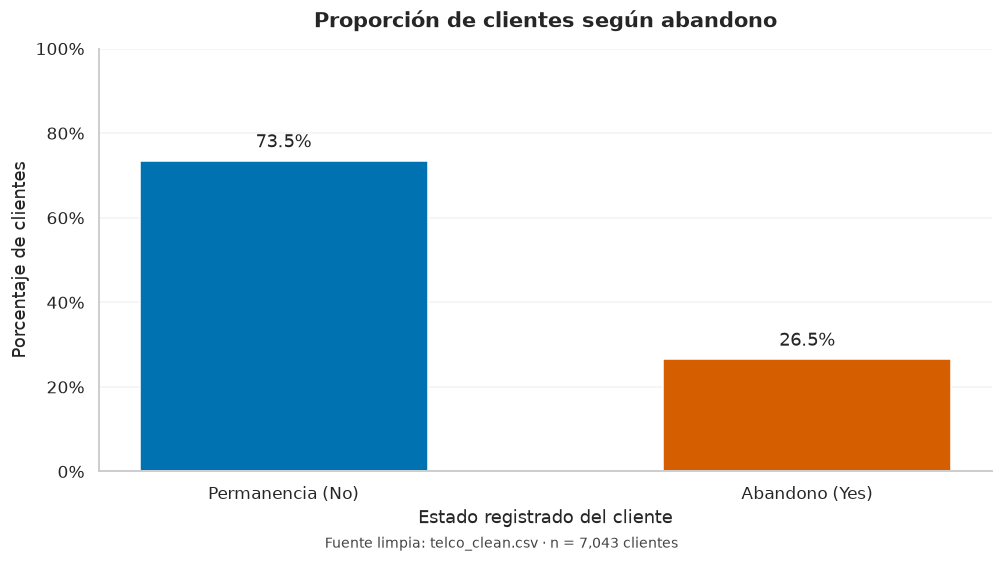

In [34]:
fig, ax = plt.subplots(layout='constrained')
barras = ax.bar(
    ['Permanencia (No)', 'Abandono (Yes)'],
    proporciones.to_numpy(),
    color=[COLORES_CHURN['No'], COLORES_CHURN['Yes']],
    width=0.55,
)
ax.set_title('Proporción de clientes según abandono', pad=14)
ax.set_xlabel('Estado registrado del cliente')
ax.set_ylabel('Porcentaje de clientes')
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.xaxis.grid(False)
ax.bar_label(barras, labels=[f'{valor:.1%}' for valor in proporciones], padding=6)
estado_fuente = 'provisoria' if fuente_provisoria else 'limpia'
fig.supxlabel(
    f'Fuente {estado_fuente}: {ruta_datos.name} · n = {len(df):,} clientes',
    fontsize=9,
    color='#444444',
)

ruta_figura = guardar_figura(fig, '16_ejemplo_churn')
plt.show()
plt.close(fig)
print(f'Figura exportada: {ruta_figura.relative_to(RAIZ).as_posix()}')
print(f'Churn observado en la fuente: {proporciones.loc["Yes"]:.1%}')


#### Interpretación del ejemplo

En el archivo limpio, aproximadamente el **26,5 %** de los 7.043 clientes tiene `Churn = Yes` y el **73,5 %** tiene `Churn = No`. Hay más clientes con permanencia registrada, por lo que el conteo de aciertos de un futuro clasificador deberá compararse con la línea base de predecir siempre la clase mayoritaria, como pide la tarea 27.

Este gráfico describe la composición de la muestra; no identifica causas de abandono ni demuestra la efectividad de una campaña. Cuando se genere el dataset limpio, se debe revisar la interpretación con las tasas que imprima la celda anterior. La imagen se regenera automáticamente usando la fuente limpia si está disponible.


## Tarea 17 · Histogramas con KDE de antigüedad y cargo mensual

Origen — `17_histogramas_kde.ipynb`.

### 1. Estilo común del TPI

Celda definida en la tarea 16: importaciones, detección de la raíz del proyecto, paleta (`No` en azul, `Yes` en naranja) y las funciones `aplicar_estilo()` y `guardar_figura(fig, nombre)`.

### 2. Carga del dataset limpio

Leemos `telco_clean.csv`, generado en la tarea 9. Solo necesitamos las dos variables numéricas y `Churn`. Verificamos que no falten datos y que `Churn` tenga solo las etiquetas esperadas.

In [35]:
import numpy as np
import pandas as pd

GITHUB_REPO = 'julianschmidt1/tpi-analisis-de-datos'
GITHUB_REF = 'main'
RUTA_LIMPIA = Path('data/processed/telco_clean.csv')

if EN_COLAB:
    fuente = (
        f'https://raw.githubusercontent.com/{GITHUB_REPO}/'
        f'{GITHUB_REF}/{RUTA_LIMPIA.as_posix()}'
    )
else:
    fuente = RAIZ / RUTA_LIMPIA

df = pd.read_csv(fuente, usecols=['tenure', 'MonthlyCharges', 'Churn'])

assert not df.isna().any().any(), 'El dataset limpio no debe tener nulos.'
assert df['Churn'].isin(['No', 'Yes']).all(), 'Revisá las etiquetas de Churn.'

print(f'Fuente: {fuente}')
print(f'Clientes analizados: {len(df):,}')
display_cols = df[['tenure', 'MonthlyCharges']].describe().round(2)
display_cols

Fuente: .\data\processed\telco_clean.csv
Clientes analizados: 7,043
Out[35]: 
        tenure  MonthlyCharges
count  7043.00         7043.00
mean     32.37           64.76
std      24.56           30.09
min       0.00           18.25
25%       9.00           35.50
50%      29.00           70.35
75%      55.00           89.85
max      72.00          118.75


### 3. Antigüedad del cliente (`tenure`)

`tenure` es la cantidad de meses que el cliente lleva en la empresa. A la izquierda vemos la distribución de **todos** los clientes; a la derecha, la comparación entre quienes **se quedaron** (`No`) y quienes **se fueron** (`Yes`). Usamos la escala de densidad en el panel derecho para comparar las formas aunque haya muchos más clientes que se quedan que clientes que se van.

Figura exportada: reports/figures/17_histograma_tenure.png


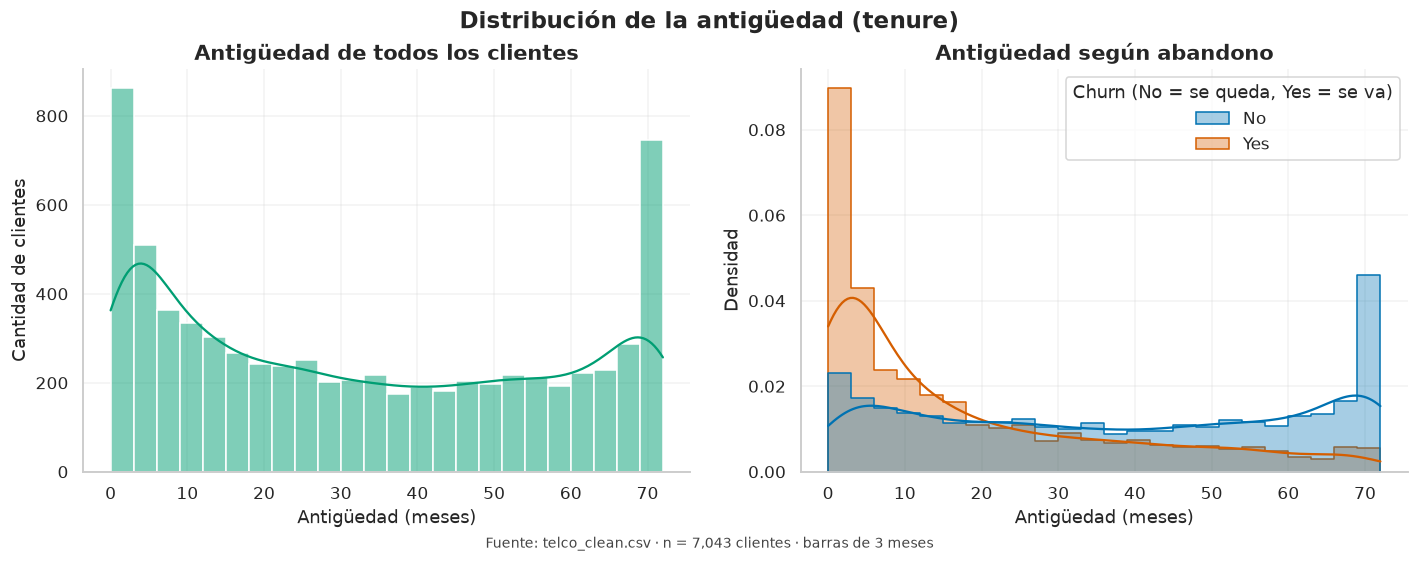

In [36]:
fig, (ax_total, ax_churn) = plt.subplots(1, 2, figsize=(13, 5), layout='constrained', sharex=True)
fig.get_layout_engine().set(w_pad=0.15)

sns.histplot(
    data=df, x='tenure', binwidth=3, binrange=(0, 72),
    kde=True, kde_kws={'clip': (0, 72)},
    color=PALETA_CATEGORICA[2], edgecolor='white', ax=ax_total,
)
ax_total.set_title('Antigüedad de todos los clientes')
ax_total.set_xlabel('Antigüedad (meses)')
ax_total.set_ylabel('Cantidad de clientes')

sns.histplot(
    data=df, x='tenure', hue='Churn', hue_order=['No', 'Yes'], palette=COLORES_CHURN,
    binwidth=3, binrange=(0, 72), stat='density', common_norm=False,
    element='step', fill=True, alpha=0.35,
    kde=True, kde_kws={'clip': (0, 72)}, ax=ax_churn,
)
ax_churn.set_title('Antigüedad según abandono')
ax_churn.set_xlabel('Antigüedad (meses)')
ax_churn.set_ylabel('Densidad')
ax_churn.legend_.set_title('Churn (No = se queda, Yes = se va)')

fig.suptitle('Distribución de la antigüedad (tenure)', fontsize=15, fontweight='bold')
fig.supxlabel(f'Fuente: telco_clean.csv · n = {len(df):,} clientes · barras de 3 meses', fontsize=9, color='#444444')

ruta = guardar_figura(fig, '17_histograma_tenure')
plt.show()
plt.close(fig)
print(f'Figura exportada: {ruta.relative_to(RAIZ).as_posix()}')

In [37]:
t = df['tenure']
print(f'Media: {t.mean():.1f} meses · Mediana: {t.median():.1f} meses')
print(f'Clientes con 6 meses o menos: {(t <= 6).mean():.1%}')
print(f'Clientes con el máximo de 72 meses: {(t == 72).sum():,} ({(t == 72).mean():.1%})')
print()
print('Antigüedad mediana según Churn (meses):')
print(df.groupby('Churn')['tenure'].median().to_string())
print()
print(f'Tasa de abandono con 6 meses o menos: {(df.loc[t <= 6, "Churn"] == "Yes").mean():.1%}')
print(f'Tasa de abandono con 61 meses o más: {(df.loc[t >= 61, "Churn"] == "Yes").mean():.1%}')

Media: 32.4 meses · Mediana: 29.0 meses
Clientes con 6 meses o menos: 21.0%
Clientes con el máximo de 72 meses: 362 (5.1%)

Antigüedad mediana según Churn (meses):
Churn
No     38.0
Yes    10.0

Tasa de abandono con 6 meses o menos: 52.9%
Tasa de abandono con 61 meses o más: 6.6%


#### Interpretación de la antigüedad

- **La distribución tiene dos picos.** Hay una concentración de clientes muy nuevos (alrededor del 21 % tiene 6 meses o menos) y otra de clientes muy antiguos (362 llegan al máximo de 72 meses). Entre ambos extremos hay menos clientes. La media (32,4 meses) y la mediana (29 meses) quedan en una zona intermedia donde casi no hay un grupo típico, por lo que conviene no resumir la antigüedad con un solo promedio.
- **Quienes se van tienen mucha menos antigüedad.** La mediana de antigüedad de quienes se van es de 10 meses, frente a 38 meses de quienes se quedan. En el panel derecho, la curva naranja se concentra a la izquierda (primeros meses) y la azul se reparte hacia la derecha.
- **El riesgo es mayor al inicio de la relación.** La tasa de abandono es de 52,9 % entre clientes con 6 meses o menos y de 6,6 % entre quienes llevan 61 meses o más.

**Para el negocio:** los primeros meses son el momento crítico. Conviene concentrar los esfuerzos de retención (bienvenida, seguimiento, ofertas) en clientes nuevos. Es una asociación observada en los datos: no prueba por sí sola que la antigüedad cause el abandono, ya que los clientes nuevos pueden diferir en otros aspectos, como el tipo de contrato.

### 4. Cargo mensual (`MonthlyCharges`)

`MonthlyCharges` es lo que paga el cliente por mes. Mismo esquema: a la izquierda, todos los clientes; a la derecha, la comparación entre quienes se quedan y quienes se van.

Figura exportada: reports/figures/17_histograma_cargo_mensual.png


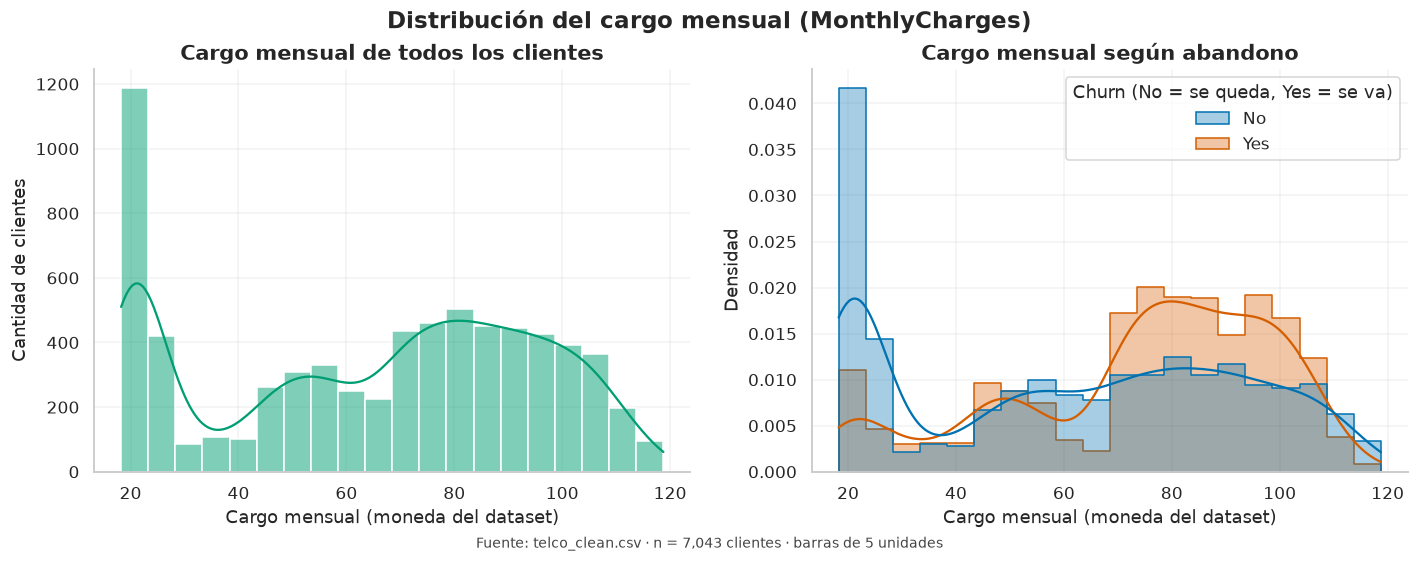

In [38]:
minimo, maximo = df['MonthlyCharges'].min(), df['MonthlyCharges'].max()

fig, (ax_total, ax_churn) = plt.subplots(1, 2, figsize=(13, 5), layout='constrained', sharex=True)
fig.get_layout_engine().set(w_pad=0.15)

sns.histplot(
    data=df, x='MonthlyCharges', binwidth=5,
    kde=True, kde_kws={'clip': (minimo, maximo)},
    color=PALETA_CATEGORICA[2], edgecolor='white', ax=ax_total,
)
ax_total.set_title('Cargo mensual de todos los clientes')
ax_total.set_xlabel('Cargo mensual (moneda del dataset)')
ax_total.set_ylabel('Cantidad de clientes')

sns.histplot(
    data=df, x='MonthlyCharges', hue='Churn', hue_order=['No', 'Yes'], palette=COLORES_CHURN,
    binwidth=5, stat='density', common_norm=False,
    element='step', fill=True, alpha=0.35,
    kde=True, kde_kws={'clip': (minimo, maximo)}, ax=ax_churn,
)
ax_churn.set_title('Cargo mensual según abandono')
ax_churn.set_xlabel('Cargo mensual (moneda del dataset)')
ax_churn.set_ylabel('Densidad')
ax_churn.legend_.set_title('Churn (No = se queda, Yes = se va)')

fig.suptitle('Distribución del cargo mensual (MonthlyCharges)', fontsize=15, fontweight='bold')
fig.supxlabel(f'Fuente: telco_clean.csv · n = {len(df):,} clientes · barras de 5 unidades', fontsize=9, color='#444444')

ruta = guardar_figura(fig, '17_histograma_cargo_mensual')
plt.show()
plt.close(fig)
print(f'Figura exportada: {ruta.relative_to(RAIZ).as_posix()}')

In [39]:
m = df['MonthlyCharges']
print(f'Media: {m.mean():.2f} · Mediana: {m.median():.2f}')
print(f'Clientes que pagan menos de 30: {(m < 30).mean():.1%}')
print(f'Clientes que pagan entre 70 y 100: {((m >= 70) & (m <= 100)).mean():.1%}')
print()
print('Cargo mensual mediano según Churn:')
print(df.groupby('Churn')['MonthlyCharges'].median().round(2).to_string())
print()
print(f'Tasa de abandono con cargo menor a 30: {(df.loc[m < 30, "Churn"] == "Yes").mean():.1%}')
print(f'Tasa de abandono con cargo entre 70 y 100: {(df.loc[(m >= 70) & (m <= 100), "Churn"] == "Yes").mean():.1%}')

Media: 64.76 · Mediana: 70.35
Clientes que pagan menos de 30: 23.5%
Clientes que pagan entre 70 y 100: 38.2%

Cargo mensual mediano según Churn:
Churn
No     64.43
Yes    79.65

Tasa de abandono con cargo menor a 30: 9.8%
Tasa de abandono con cargo entre 70 y 100: 38.0%


#### Interpretación del cargo mensual

- **Hay dos grupos de clientes según lo que pagan.** Un grupo grande paga poco (el 23,5 % paga menos de 30, con un pico marcado alrededor de 20) y otro grupo paga bastante (el 38,2 % paga entre 70 y 100). En el medio hay pocos clientes. Por eso la media (64,76) queda por debajo de la mediana (70,35) y tampoco describe bien a ninguno de los dos grupos.
- **Quienes se van pagan más.** La mediana de cargo mensual de quienes se van es de 79,65, frente a 64,43 de quienes se quedan. En el panel derecho, la curva naranja pesa más hacia los cargos altos y la azul tiene un pico en los cargos bajos.
- **Los cargos bajos casi no abandonan.** La tasa de abandono es de 9,8 % entre quienes pagan menos de 30 y de 38,0 % entre quienes pagan entre 70 y 100.

**Para el negocio:** el abandono se concentra en los clientes que pagan más. Conviene revisar si ese cargo alto responde a servicios adicionales de valor percibido y evaluar ofertas o planes ajustados para ese segmento. Es una asociación, no una causa: los cargos altos suelen venir acompañados de ciertos servicios (por ejemplo, fibra óptica) o tipos de contrato que también pueden influir en el abandono, y eso se investiga en las otras tareas de EDA.

### 5. Conclusión de la tarea

En estas comparaciones por separado, la tasa de baja es mayor entre clientes recientes y también en el tramo de cargos de 70 a 100 frente al de menos de 30. Para saber qué ocurre entre quienes cumplen ambas condiciones, hace falta cruzar antigüedad y cargo mensual. Las dos figuras quedaron exportadas en `reports/figures/` (`17_histograma_tenure.png` y `17_histograma_cargo_mensual.png`) para el informe y la defensa.

## Tarea 18 · Heatmap de correlación

Origen — `18_heatmap_correlacion.ipynb`.

### 1. Estilo común

Reutilizamos la celda del punto 16, que aplica la tipografía y la paleta del equipo y configura la exportación PNG a 300 dpi.

### 2. Carga de datos

Leemos el dataset limpio generado durante esta ejecución.

In [40]:
from pathlib import Path
from urllib.error import HTTPError

import pandas as pd

EN_COLAB = False

variables = ["tenure", "MonthlyCharges", "TotalCharges"]
ruta_limpia = Path("data/processed/telco_clean.csv")
ruta_provisoria = Path("data/processed/telco_provisorio.csv")

if EN_COLAB:
    url_repo = "https://raw.githubusercontent.com/julianschmidt1/tpi-analisis-de-datos/main/"
    fuente = url_repo + ruta_limpia.as_posix()
    try:
        datos = pd.read_csv(fuente, usecols=variables)
    except HTTPError as error:
        if error.code != 404:
            raise
        fuente = url_repo + ruta_provisoria.as_posix()
        datos = pd.read_csv(fuente, usecols=variables)
else:
    actual = Path.cwd().resolve()
    raiz = next(
        (ruta for ruta in (actual, *actual.parents)
         if (ruta / ruta_limpia).is_file() or (ruta / ruta_provisoria).is_file()),
        None,
    )
    if raiz is None:
        raise FileNotFoundError("Falta el CSV de la tarea 3 o el dataset limpio de la tarea 9.")
    fuente = raiz / ruta_limpia
    if not fuente.is_file():
        fuente = raiz / ruta_provisoria
    datos = pd.read_csv(fuente, usecols=variables)

datos = datos[variables]
print(f"Fuente: {fuente}")

Fuente: .\data\processed\telco_clean.csv


### 3. Heatmap de Pearson

Calculamos Pearson con el mismo criterio del punto 11. Cada celda muestra el coeficiente con tres decimales. Usamos una escala divergente de −1 a 1 centrada en cero para distinguir el signo y la intensidad de la asociación. La diagonal vale 1 porque compara cada variable consigo misma.

Figura exportada: reports/figures/18_heatmap_correlacion.png


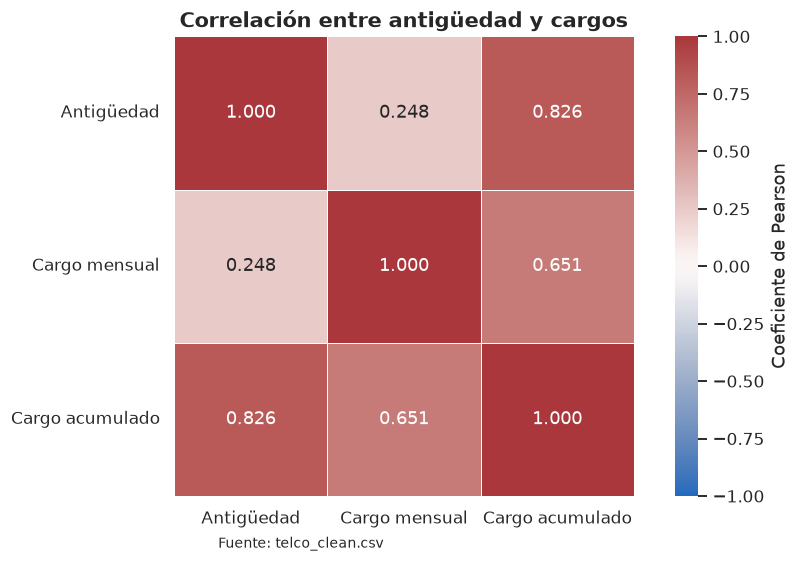

In [41]:
pearson = datos.corr(method="pearson")
etiquetas = ["Antigüedad", "Cargo mensual", "Cargo acumulado"]

fig, ax = plt.subplots(layout="constrained")
sns.heatmap(
    pearson, annot=True, fmt=".3f", cmap=MAPA_CORRELACION,
    vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
    xticklabels=etiquetas, yticklabels=etiquetas,
    cbar_kws={"label": "Coeficiente de Pearson"}, ax=ax,
)
ax.set_title("Correlación entre antigüedad y cargos")
ax.tick_params(axis="x", labelrotation=0)
ax.tick_params(axis="y", labelrotation=0)
nombre_fuente = str(fuente).rsplit("/", 1)[-1] if EN_COLAB else fuente.name
fig.supxlabel(f"Fuente: {nombre_fuente}", fontsize=9)

ruta_figura = guardar_figura(fig, "18_heatmap_correlacion")
print(f"Figura exportada: {ruta_figura.relative_to(RAIZ).as_posix()}")
plt.show()
plt.close(fig)

### 4. Interpretación con el CSV limpio

La celda de mayor correlación fuera de la diagonal une **antigüedad y cargo acumulado (0,826)**. Quienes llevan más meses en la empresa tienden a acumular más cargos. El cargo mensual también se asocia con el acumulado (0,651). La asociación entre antigüedad y cargo mensual es más débil (0,248), así que los meses de servicio dan poca información sobre cuánto paga un cliente cada mes.

Con `telco_clean.csv`, las tres comparaciones usan los 7.043 clientes.

## Tarea 19 · Tasa de baja por contrato y método de pago

Origen — `19_barras_churn.ipynb`.

### 1. Estilo común

Usamos la celda del punto 16 para mantener la tipografía, el color de las bajas y la exportación a 300 dpi.

### 2. Carga de datos

Leemos el dataset limpio generado durante esta ejecución.

In [42]:
from pathlib import Path
from urllib.error import HTTPError

import pandas as pd

EN_COLAB = False

variables = ["Contract", "PaymentMethod", "Churn"]
ruta_limpia = Path("data/processed/telco_clean.csv")
ruta_provisoria = Path("data/processed/telco_provisorio.csv")

if EN_COLAB:
    url_repo = "https://raw.githubusercontent.com/julianschmidt1/tpi-analisis-de-datos/main/"
    fuente = url_repo + ruta_limpia.as_posix()
    try:
        datos = pd.read_csv(fuente, usecols=variables)
    except HTTPError as error:
        if error.code != 404:
            raise
        fuente = url_repo + ruta_provisoria.as_posix()
        datos = pd.read_csv(fuente, usecols=variables)
else:
    actual = Path.cwd().resolve()
    raiz = next(
        (ruta for ruta in (actual, *actual.parents)
         if (ruta / ruta_limpia).is_file() or (ruta / ruta_provisoria).is_file()),
        None,
    )
    if raiz is None:
        raise FileNotFoundError("Falta el CSV de la tarea 3 o el dataset limpio de la tarea 9.")
    fuente = raiz / ruta_limpia
    if not fuente.is_file():
        fuente = raiz / ruta_provisoria
    datos = pd.read_csv(fuente, usecols=variables)

datos = datos[variables]
print(f"Fuente: {fuente}")

Fuente: .\data\processed\telco_clean.csv


### 3. Cálculo y formato de las barras

En cada categoría, dividimos las bajas (`Churn = Yes`) por el total de clientes de esa categoría. Ambos gráficos usan una escala del 0 al 100 % y muestran el porcentaje de cada barra. La línea punteada indica la tasa de toda la cartera para facilitar la comparación.

In [43]:
assert not datos.empty and datos["Churn"].isin(["Yes", "No"]).all(), "Revisá los valores de Churn."
bajas = datos["Churn"].eq("Yes")
tasa_general = bajas.mean()
nombre_fuente = str(fuente).rsplit("/", 1)[-1] if EN_COLAB else fuente.name

def graficar_tasa_baja(columna, etiquetas, titulo, nombre_archivo):
    grupos = datos[columna].map(etiquetas).fillna(datos[columna]).fillna("Sin dato")
    tasas = bajas.groupby(grupos).mean().sort_values()

    fig, ax = plt.subplots(layout="constrained")
    barras = ax.barh(tasas.index, tasas, color=COLORES_CHURN["Yes"])
    ax.bar_label(
        barras, labels=[f"{tasa:.2%}" for tasa in tasas], padding=5,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1},
    )
    ax.axvline(tasa_general, color="#444444", linestyle="--", label=f"Cartera: {tasa_general:.2%}")
    ax.set(xlim=(0, 1), xlabel="Porcentaje de clientes que se dieron de baja", title=titulo)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.yaxis.grid(False)
    ax.legend(loc="lower right")
    fig.supxlabel(f"Fuente: {nombre_fuente} · n = {len(datos):,}", fontsize=9)

    ruta_figura = guardar_figura(fig, nombre_archivo)
    print(f"Figura exportada: {ruta_figura.relative_to(RAIZ).as_posix()}")
    plt.show()
    plt.close(fig)
    return tasas

### 4. Tasa de baja por contrato

Comparamos la proporción de bajas entre clientes con contratos mensuales, anuales y de dos años.

Figura exportada: reports/figures/19_churn_por_contrato.png


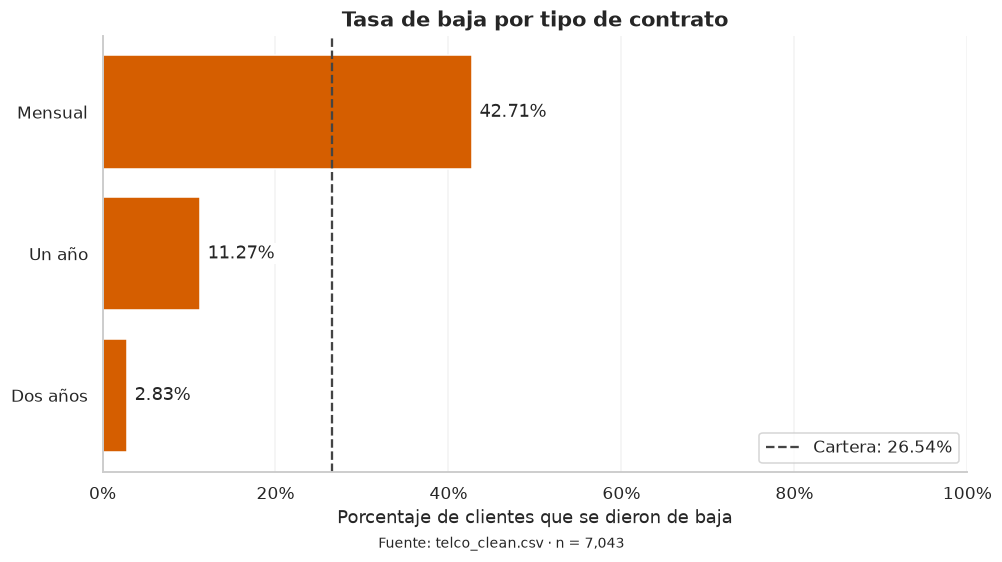

In [44]:
tasas_contrato = graficar_tasa_baja(
    "Contract",
    {"Month-to-month": "Mensual", "One year": "Un año", "Two year": "Dos años"},
    "Tasa de baja por tipo de contrato",
    "19_churn_por_contrato",
)

Con el CSV limpio, el contrato **mensual** registra la mayor tasa de baja (42,71 %), frente al 11,27 % en contratos de un año y al 2,83 % en los de dos años. Es el único tipo de contrato por encima de la tasa general de 26,54 %.

### 5. Tasa de baja por método de pago

Comparamos la proporción de bajas entre clientes que usan cheque electrónico, cheque por correo, transferencia automática o tarjeta de crédito automática.

Figura exportada: reports/figures/19_churn_por_metodo_de_pago.png


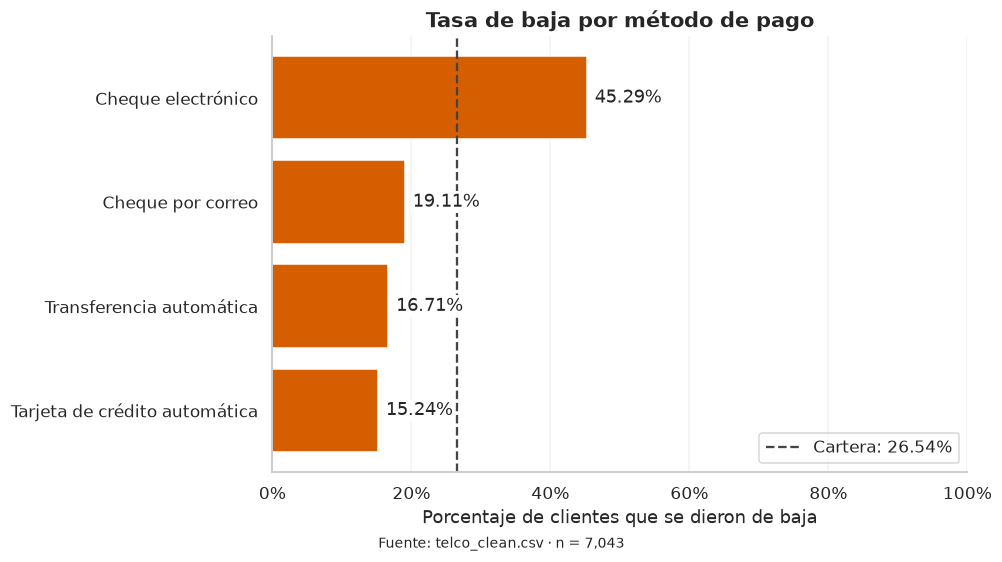

In [45]:
tasas_pago = graficar_tasa_baja(
    "PaymentMethod",
    {
        "Electronic check": "Cheque electrónico",
        "Mailed check": "Cheque por correo",
        "Bank transfer (automatic)": "Transferencia automática",
        "Credit card (automatic)": "Tarjeta de crédito automática",
    },
    "Tasa de baja por método de pago",
    "19_churn_por_metodo_de_pago",
)

Con el CSV limpio, **cheque electrónico** tiene la mayor tasa de baja (45,29 %). Le siguen cheque por correo (19,11 %), transferencia automática (16,71 %) y tarjeta de crédito automática (15,24 %). La diferencia permite identificar un grupo con más bajas observadas. Para entenderla, también importa cómo se distribuyen los tipos de contrato y servicio entre los métodos de pago.


## Tarea 25 · Regresión lineal del cargo acumulado

Origen — `25_regresion_lineal.ipynb`.

### 1. Carga de datos

Usamos el dataset limpio del punto 9. Revisamos que ambas variables sean numéricas, finitas y completas antes de ajustar el modelo.

In [46]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

EN_COLAB = False

ruta_datos = Path("data/processed/telco_clean.csv")
if EN_COLAB:
    fuente = (
        "https://raw.githubusercontent.com/julianschmidt1/tpi-analisis-de-datos/main/"
        + ruta_datos.as_posix()
    )
else:
    actual = Path.cwd().resolve()
    fuente = next(
        (base / ruta_datos for base in (actual, *actual.parents)
         if (base / ruta_datos).is_file()),
        None,
    )
    if fuente is None:
        raise FileNotFoundError("Falta telco_clean.csv. Ejecutá primero la tarea 9.")

datos = pd.read_csv(fuente, usecols=["tenure", "TotalCharges"])
assert all(pd.api.types.is_numeric_dtype(datos[columna]) for columna in datos)
assert np.isfinite(datos.to_numpy()).all(), "Revisá faltantes o valores infinitos."
print(f"Fuente: {fuente}")
print(f"Clientes: {len(datos):,}")

Fuente: .\data\processed\telco_clean.csv
Clientes: 7,043


### 2. Partición y ajuste

El predictor es la antigüedad en meses y el objetivo es el cargo acumulado. Reservamos un 20 % de los clientes para evaluar el modelo y entrenamos con el otro 80 %, usando `random_state=42` para reproducir la división. Esta tarea tiene su propia partición, como indica el plan.

El modelo ajusta una recta con la forma cargo estimado = intercepto + coeficiente × antigüedad. Aprende los dos parámetros únicamente con entrenamiento.

In [47]:
X = datos[["tenure"]]
y = datos["TotalCharges"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

modelo = LinearRegression()
modelo.fit(X_train, y_train)
coeficiente = modelo.coef_[0]
intercepto = modelo.intercept_

print(f"Entrenamiento: {len(X_train):,} clientes")
print(f"Prueba: {len(X_test):,} clientes")
print(f"Cargo estimado = {intercepto:.2f} + {coeficiente:.2f} × antigüedad")

Entrenamiento: 5,634 clientes
Prueba: 1,409 clientes
Cargo estimado = -196.86 + 76.73 × antigüedad


### 3. Evaluación sobre prueba

R² compara los errores cuadrados del modelo con la variación del objetivo en prueba. Un valor de 1 corresponde a un ajuste perfecto y puede ser negativo si los errores son grandes. MAE es el promedio de las diferencias absolutas entre los cargos observados y los estimados, expresado en las mismas unidades monetarias que el cargo acumulado.

In [48]:
predicciones = modelo.predict(X_test)
r2 = r2_score(y_test, predicciones)
mae = mean_absolute_error(y_test, predicciones)

metricas = pd.DataFrame({
    "Métrica": ["R² en prueba", "MAE en prueba"],
    "Valor": [r2, mae],
})
print(metricas.to_string(index=False, float_format=lambda valor: f"{valor:.4f}"))
r2_regresion = r2
mae_regresion = mae


      Métrica    Valor
 R² en prueba   0.6701
MAE en prueba 892.3789


### 4. Interpretación

Interpretamos los resultados impresos por las celdas anteriores. El coeficiente describe una asociación promedio entre la antigüedad y el total facturado en esta muestra. Los clientes tienen distintos planes y cargos mensuales, por lo que la antigüedad por sí sola deja parte de la variación sin explicar.

In [49]:
print(
    f"Por cada mes adicional de antigüedad, la recta estima "
    f"{coeficiente:.2f} unidades monetarias más de cargo acumulado."
)
print(
    f"En los clientes de prueba, R² = {r2:.3f}. "
    f"El error absoluto promedio es de {mae:.2f} unidades monetarias."
)
print(
    f"El intercepto es {intercepto:.2f}: es el valor de la recta a cero meses. "
    "Un intercepto negativo carece de interpretación como cargo real "
    "y muestra una limitación del ajuste lineal cerca del origen."
)

Por cada mes adicional de antigüedad, la recta estima 76.73 unidades monetarias más de cargo acumulado.
En los clientes de prueba, R² = 0.670. El error absoluto promedio es de 892.38 unidades monetarias.
El intercepto es -196.86: es el valor de la recta a cero meses. Un intercepto negativo carece de interpretación como cargo real y muestra una limitación del ajuste lineal cerca del origen.


## Tarea 21 · Partición de datos y codificación del objetivo

Origen — `21_particion_datos.ipynb`.

### 1. Carga del dataset limpio

Buscamos la raíz del repositorio desde el directorio actual o sus padres. En Colab usamos el CSV publicado. Validamos el objetivo antes de codificarlo.

In [50]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

EN_COLAB = False

if EN_COLAB:
    RAIZ = Path.cwd()
    fuente = 'https://raw.githubusercontent.com/julianschmidt1/tpi-analisis-de-datos/main/data/processed/telco_clean.csv'
else:
    actual = Path.cwd().resolve()
    RAIZ = next((ruta for ruta in (actual, *actual.parents)
                 if (ruta / 'data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv').is_file()), None)
    if RAIZ is None:
        raise FileNotFoundError('Abrí Jupyter dentro del repositorio del TPI.')
    fuente = RAIZ / 'data' / 'processed' / 'telco_clean.csv'

df = pd.read_csv(fuente)
assert df.index.is_unique
assert not df.isna().any().any(), 'La entrada debe ser el dataset limpio, sin nulos.'
assert set(df['Churn'].unique()) == {'No', 'Yes'}
assert 'customerID' not in df.columns
print(f'Dataset limpio: {df.shape[0]:,} clientes y {df.shape[1]} columnas.')

Dataset limpio: 7,043 clientes y 22 columnas.


### 2. Predictores y objetivo

`X` contiene todas las columnas excepto `Churn`. `LabelEncoder` se aplica exclusivamente al objetivo: `No` corresponde a 0 y `Yes` a 1. Esta equivalencia fija no aprende estadísticas de los predictores. Las categorías de entrada y sus escalas se ajustarán después de partir, usando solo entrenamiento.

In [51]:
X = df.drop(columns='Churn').copy()
label_encoder = LabelEncoder()
y = pd.Series(label_encoder.fit_transform(df['Churn']), index=df.index, name='Churn')
mapeo = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
assert mapeo == {'No': 0, 'Yes': 1}
assert 'Churn' not in X.columns
assert X.index.equals(y.index)
print(f'Codificación: {mapeo}')
print(f'Predictores por cliente: {X.shape[1]}')

Codificación: {'No': np.int64(0), 'Yes': np.int64(1)}
Predictores por cliente: 21


### 3. Partición estratificada 80/20

Reservamos test antes de codificar o escalar los predictores. La estratificación conserva la proporción de bajas y `random_state=42` permite repetir la misma partición. Los índices identifican las filas del CSV de entrada, no son una variable predictora.

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42,
)

resumen = pd.DataFrame({
    nombre: {'clientes': len(objetivo), 'bajas': int(objetivo.sum()),
             'tasa_churn_pct': objetivo.mean() * 100}
    for nombre, objetivo in [('Total', y), ('Train', y_train), ('Test', y_test)]
}).T
resumen[['clientes', 'bajas']] = resumen[['clientes', 'bajas']].astype(int)
display(resumen.round(4))

,clientes,bajas,tasa_churn_pct
Total,7043,1869,26.5370
Train,5634,1495,26.5353
Test,1409,374,26.5436


La tabla permite comparar la tasa de bajas de cada conjunto con la cartera completa. La división 80/20 se redondea a clientes enteros; las diferencias mínimas en las tasas son esperables. Mantener esa composición evita evaluar el modelo con una proporción de bajas artificialmente distinta.

### 4. Verificaciones de la partición

Comprobamos que cada cliente aparezca una sola vez, que las etiquetas sigan alineadas y que la diferencia de tasas sea menor a 0,1 puntos porcentuales. También verificamos que los predictores conserven sus valores originales: todavía no se ajustó ningún codificador ni escalador sobre ellos.

In [53]:
assert X_train.index.intersection(X_test.index).empty
assert len(X_train) + len(X_test) == len(df)
assert set(X_train.index) | set(X_test.index) == set(df.index)
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert abs(y_train.mean() - y_test.mean()) < 0.001
pd.testing.assert_frame_equal(X_train, X.loc[X_train.index])
pd.testing.assert_frame_equal(X_test, X.loc[X_test.index])
pd.testing.assert_series_equal(y_train, y.loc[y_train.index])
pd.testing.assert_series_equal(y_test, y.loc[y_test.index])
print('Verificaciones correctas: sin solapamientos, sin pérdida de filas y etiquetas alineadas.')
print(f'Diferencia de churn train/test: {abs(y_train.mean() - y_test.mean()) * 100:.4f} puntos porcentuales.')

Verificaciones correctas: sin solapamientos, sin pérdida de filas y etiquetas alineadas.
Diferencia de churn train/test: 0.0083 puntos porcentuales.


### 5. Exportación para las tareas 22 y 23

Guardamos la partición sin transformar en una subcarpeta propia. Los archivos transformados que debe producir la tarea 23 seguirán usando las rutas acordadas `data/processed/X_train.csv`, etc. Para leer esta partición, usar `pd.read_csv(ruta, index_col='fila_origen')`; para `y`, seleccionar después la columna `Churn`. Nunca incluir `fila_origen` como predictor.

Las tareas siguientes deben hacer `fit` de codificadores y escaladores únicamente con `X_train` y usar `transform` sobre `X_test`. El conjunto de prueba se reserva para la evaluación final.

In [54]:
carpeta_salida = RAIZ / 'data' / 'processed' / 'particion'
carpeta_salida.mkdir(parents=True, exist_ok=True)
for nombre, datos in [('X_train', X_train), ('X_test', X_test),
                      ('y_train', y_train), ('y_test', y_test)]:
    ruta = carpeta_salida / f'{nombre}.csv'
    datos.to_csv(ruta, index=True, index_label='fila_origen')
    recuperado = pd.read_csv(ruta, index_col='fila_origen')
    esperado = datos.to_frame() if isinstance(datos, pd.Series) else datos
    pd.testing.assert_frame_equal(recuperado.rename_axis(None), esperado)
print('Cuatro archivos exportados y verificados en:', carpeta_salida)

Cuatro archivos exportados y verificados en: .\data\processed\particion


La partición queda lista para preprocesamiento. El churn conserva su representación `Yes/No` en el dataset limpio; la codificación 0/1 se utiliza en estas etiquetas de modelado. Las columnas calculadas se conservan como predictores disponibles; la selección de variables y las transformaciones deberán justificarse en las etapas siguientes.

## Tarea 22 · Codificación de variables categóricas

Origen — `22_codificacion.ipynb`.

### 1. Carga de la partición existente

Conservamos `fila_origen` como índice para alinear clientes y etiquetas; no lo usamos como predictor. Verificamos que los conjuntos sean disjuntos y que no contengan el objetivo entre los predictores.

In [55]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

EN_COLAB = False

actual = Path.cwd().resolve()
RAIZ = actual if EN_COLAB else next(
    (ruta for ruta in (actual, *actual.parents)
     if (ruta / 'data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv').is_file()), None)
if RAIZ is None:
    raise FileNotFoundError('Abrí Jupyter dentro del repositorio del TPI.')
entrada = RAIZ / 'data' / 'processed' / 'particion'
archivos = ['X_train', 'X_test', 'y_train', 'y_test']
faltantes = [nombre for nombre in archivos if not (entrada / f'{nombre}.csv').is_file()]
if faltantes:
    raise FileNotFoundError(f'Faltan {faltantes} en {entrada}. Ejecutá la tarea 21 o copiá sus salidas.')
X_train = pd.read_csv(entrada / 'X_train.csv', index_col='fila_origen')
X_test = pd.read_csv(entrada / 'X_test.csv', index_col='fila_origen')
y_train = pd.read_csv(entrada / 'y_train.csv', index_col='fila_origen')['Churn']
y_test = pd.read_csv(entrada / 'y_test.csv', index_col='fila_origen')['Churn']

assert X_train.index.is_unique and X_test.index.is_unique
assert X_train.index.intersection(X_test.index).empty
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert X_train.columns.equals(X_test.columns)
assert 'Churn' not in X_train.columns
assert not X_train.isna().any().any() and not X_test.isna().any().any()
print(f'Train: {X_train.shape}; test: {X_test.shape}. Etiquetas alineadas.')

Train: (5634, 21); test: (1409, 21). Etiquetas alineadas.


### 2. Decisiones de codificación

Usamos **One-Hot completo para `PaymentMethod`**: cada método conserva su identidad sin imponer distancias ni un orden artificial. Agrupar métodos por su tasa de churn requeriría aprender del objetivo y podría introducir fuga de información. También aplicamos One-Hot completo a las demás nominales, incluidas las binarias. No eliminamos una categoría de referencia; la interpretación de coeficientes deberá considerar la redundancia entre indicadores.

Para `Contract` fijamos `Month-to-month < One year < Two year`, representados por 0, 1 y 2. El orden expresa duración y compromiso contractual; no implica que el efecto sobre churn sea lineal. El modelo posterior deberá reconocer que esta codificación introduce pasos numéricos iguales.

Detectamos las columnas a partir de entrenamiento. Las columnas numéricas, incluidas las calculadas, se conservan sin escalar para la tarea 23.

In [56]:
orden_contrato = ['Month-to-month', 'One year', 'Two year']
columnas_nominales = X_train.select_dtypes(include=['object', 'string', 'category']).columns.drop('Contract').tolist()
columnas_numericas = X_train.select_dtypes(include='number').columns.tolist()
assert set(columnas_nominales + ['Contract'] + columnas_numericas) == set(X_train.columns)
assert set(X_train['Contract']) == set(orden_contrato)

display(pd.DataFrame([
    {'tratamiento': 'One-Hot completo', 'columnas': ', '.join(columnas_nominales)},
    {'tratamiento': 'Ordinal 0, 1, 2', 'columnas': 'Contract'},
    {'tratamiento': 'Sin escalar', 'columnas': ', '.join(columnas_numericas)},
]))

,tratamiento,columnas
0,One-Hot completo,"gender, SeniorCitizen, Partner, Dependents, Ph..."
1,"Ordinal 0, 1, 2",Contract
2,Sin escalar,"tenure, MonthlyCharges, TotalCharges, ingreso_..."


La tabla documenta qué tratamiento recibe cada predictor. Los nombres y categorías de las nominales se aprenden exclusivamente en train. Un valor nominal desconocido en test produce ceros en el bloque de esa variable (`handle_unknown='ignore'`); un contrato desconocido provoca un error para revisar el dato, porque no tiene una posición definida en el orden.

### 3. Ajuste en train y transformación de test

Esta celda define el bloque de codificación que se puede integrar en el `ColumnTransformer` de la tarea 23. Aquí dejamos las numéricas como `passthrough`; en esa tarea se reemplazará ese bloque por el escalador. El único `fit_transform` recibe entrenamiento, mientras que test pasa solo por `transform`.

In [57]:
codificador = ColumnTransformer(
    transformers=[
        ('nominal', OneHotEncoder(handle_unknown='ignore', drop=None, sparse_output=False), columnas_nominales),
        ('contrato', OrdinalEncoder(categories=[orden_contrato], handle_unknown='error'), ['Contract']),
        ('numericas', 'passthrough', columnas_numericas),
    ],
    remainder='drop',
    verbose_feature_names_out=True,
)

train_codificado = codificador.fit_transform(X_train)
test_codificado = codificador.transform(X_test)
nombres = codificador.get_feature_names_out()
X_train_codificado = pd.DataFrame(train_codificado, columns=nombres, index=X_train.index)
X_test_codificado = pd.DataFrame(test_codificado, columns=nombres, index=X_test.index)
print(f'Train codificado: {X_train_codificado.shape}; test codificado: {X_test_codificado.shape}')
display(X_train_codificado.head())

Train codificado: (5634, 46); test codificado: (1409, 46)


,nominal__gender_Female,nominal__gender_Male,nominal__SeniorCitizen_No,nominal__SeniorCitizen_Yes,nominal__Partner_No,nominal__Partner_Yes,nominal__Dependents_No,nominal__Dependents_Yes,nominal__PhoneService_No,nominal__PhoneService_Yes,nominal__MultipleLines_No,nominal__MultipleLines_No phone service,nominal__MultipleLines_Yes,nominal__InternetService_DSL,nominal__InternetService_Fiber optic,nominal__InternetService_No,nominal__OnlineSecurity_No,nominal__OnlineSecurity_No internet service,nominal__OnlineSecurity_Yes,nominal__OnlineBackup_No,nominal__OnlineBackup_No internet service,nominal__OnlineBackup_Yes,nominal__DeviceProtection_No,nominal__DeviceProtection_No internet service,nominal__DeviceProtection_Yes,nominal__TechSupport_No,nominal__TechSupport_No internet service,nominal__TechSupport_Yes,nominal__StreamingTV_No,nominal__StreamingTV_No internet service,nominal__StreamingTV_Yes,nominal__StreamingMovies_No,nominal__StreamingMovies_No internet service,nominal__StreamingMovies_Yes,nominal__PaperlessBilling_No,nominal__PaperlessBilling_Yes,nominal__PaymentMethod_Bank transfer (automatic),nominal__PaymentMethod_Credit card (automatic),nominal__PaymentMethod_Electronic check,nominal__PaymentMethod_Mailed check,contrato__Contract,numericas__tenure,numericas__MonthlyCharges,numericas__TotalCharges,numericas__ingreso_estimado,numericas__diferencia_facturacion
fila_origen,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
3738,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,35.0,49.20,1701.65,1722.00,-20.35
3151,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,15.0,75.10,1151.55,1126.50,25.05
4860,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,2.0,13.0,40.55,590.35,527.15,63.20
3867,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,2.0,26.0,73.50,1905.70,1911.00,-5.30
3810,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,44.55,44.55,44.55,0.00


Cada indicador nominal vale 0 o 1; `contrato__Contract` conserva el orden definido y las cinco columnas numéricas retienen sus valores. La expansión crea más columnas, pero conserva los mismos clientes y su correspondencia con `y_train` e `y_test`. Los datos todavía requieren escalado antes de cerrar el preprocesamiento.

### 4. Verificación de categorías, orden y ausencia de texto

Contrastamos las categorías aprendidas con train, comprobamos los indicadores y verificamos el contrato contra una equivalencia explícita. Controlamos que todas las columnas sean numéricas y finitas, que las numéricas originales no hayan cambiado y que las etiquetas sigan alineadas. La auditoría también informa si test contiene categorías nominales desconocidas, sin volver a ajustar el codificador.

In [58]:
onehot = codificador.named_transformers_['nominal']
for columna, categorias in zip(columnas_nominales, onehot.categories_):
    assert set(categorias) == set(X_train[columna].unique())
assert codificador.named_transformers_['contrato'].categories_[0].tolist() == orden_contrato

for original, convertido, objetivo in [
    (X_train, X_train_codificado, y_train),
    (X_test, X_test_codificado, y_test),
]:
    assert convertido.index.equals(objetivo.index)
    assert convertido.columns.is_unique
    assert all(pd.api.types.is_numeric_dtype(tipo) for tipo in convertido.dtypes)
    assert np.isfinite(convertido.to_numpy()).all()
    nominales = convertido.filter(like='nominal__')
    assert nominales.isin([0, 1]).all().all()
    esperado = original['Contract'].map(dict(zip(orden_contrato, [0, 1, 2])))
    np.testing.assert_array_equal(convertido['contrato__Contract'], esperado)
    for columna in columnas_numericas:
        np.testing.assert_array_equal(convertido[f'numericas__{columna}'], original[columna])

desconocidas = pd.Series({
    columna: int((~X_test[columna].isin(categorias)).sum())
    for columna, categorias in zip(columnas_nominales, onehot.categories_)
}, name='filas_test_con_categoria_desconocida')
display(desconocidas.to_frame())
print('Verificaciones correctas: orden contractual, categorías de train y matrices numéricas sin nulos.')

Verificaciones correctas: orden contractual, categorías de train y matrices numéricas sin nulos.


,filas_test_con_categoria_desconocida
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0
DeviceProtection,0


La auditoría permite detectar casos que no estaban representados en entrenamiento. No se agregan categorías aprendidas de test: se respeta el vocabulario de train. La comprobación del orden contractual verifica explícitamente que 0 significa mensual, 1 un año y 2 dos años.

### 5. Exportación y continuidad

Guardamos únicamente los predictores codificados en una subcarpeta intermedia para no ocupar las rutas finales de la tarea 23. Leemos de nuevo los archivos y verificamos su contenido. Las etiquetas siguen disponibles en `data/processed/particion/`.

Para la tarea 23, integrar este esquema con el escalador en un único `preprocessor`, ajustado sobre `X_train` original. Evitar aplicar de nuevo One-Hot a los CSV ya codificados. Las rutas finales `data/processed/X_train.csv`, `X_test.csv`, `y_train.csv` y `y_test.csv` quedan reservadas para esa tarea.

In [59]:
salida = RAIZ / 'data' / 'processed' / 'codificacion'
salida.mkdir(parents=True, exist_ok=True)
for nombre, datos in [('X_train', X_train_codificado), ('X_test', X_test_codificado)]:
    ruta = salida / f'{nombre}.csv'
    datos.to_csv(ruta, index=True, index_label='fila_origen')
    recuperado = pd.read_csv(ruta, index_col='fila_origen')
    pd.testing.assert_frame_equal(recuperado, datos, check_dtype=False)
print('Matrices codificadas exportadas y verificadas en:', salida)

Matrices codificadas exportadas y verificadas en: .\data\processed\codificacion


**Resultado:** predictores sin texto y contrato ordenado. La decisión para `PaymentMethod` queda documentada como One-Hot completo. No se ajustaron transformaciones sobre test ni se usó `Churn` para determinar categorías. El escalado y la exportación final corresponden a la tarea 23.

## Tarea 23 · Escalado e integración del preprocesamiento

Origen — `23_escalado.ipynb`.

### 1. Carga y validación de la partición

Leemos `fila_origen` como índice, nunca como predictor. Conservamos los clientes y las etiquetas de la tarea 21. Comprobamos alineación, ausencia de nulos y separación entre train y test antes de ajustar transformaciones.

In [60]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler

EN_COLAB = False

actual = Path.cwd().resolve()
RAIZ = actual if EN_COLAB else next(
    (p for p in (actual, *actual.parents) if (p / 'data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv').is_file()), None)
if RAIZ is None:
    raise FileNotFoundError('Abrí Jupyter dentro del repositorio del TPI.')
entrada = RAIZ / 'data' / 'processed' / 'particion'
archivos = ['X_train', 'X_test', 'y_train', 'y_test']
faltantes = [n for n in archivos if not (entrada / f'{n}.csv').is_file()]
if faltantes:
    raise FileNotFoundError(f'Faltan {faltantes} en {entrada}. Ejecutá la tarea 21 o copiá sus salidas.')
X_train = pd.read_csv(entrada / 'X_train.csv', index_col='fila_origen')
X_test = pd.read_csv(entrada / 'X_test.csv', index_col='fila_origen')
y_train = pd.read_csv(entrada / 'y_train.csv', index_col='fila_origen')['Churn']
y_test = pd.read_csv(entrada / 'y_test.csv', index_col='fila_origen')['Churn']
assert X_train.index.is_unique and X_test.index.is_unique
assert X_train.index.intersection(X_test.index).empty
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert X_train.columns.equals(X_test.columns)
assert 'Churn' not in X_train.columns and 'fila_origen' not in X_train.columns
assert set(y_train.unique()) == set(y_test.unique()) == {0, 1}
assert not X_train.isna().any().any() and not X_test.isna().any().any()
print(f'Train: {X_train.shape}; test: {X_test.shape}. Etiquetas alineadas.')

Train: (5634, 21); test: (1409, 21). Etiquetas alineadas.


### 2. Esquema integrado y decisiones

Reutilizamos One-Hot completo para las nominales, incluido `PaymentMethod`, y el orden contractual mensual=0, un año=1, dos años=2. Las categorías nominales se aprenden solo de train; las desconocidas se ignoran. Un contrato desconocido produce un error para revisar el dato.

Escalamos `tenure`, `MonthlyCharges`, `TotalCharges` y las columnas calculadas `ingreso_estimado` y `diferencia_facturacion`: dejar estas últimas sin escalar mantendría diferencias grandes de magnitud. No escalamos los indicadores One-Hot ni el contrato ordinal. El escalado no elimina la redundancia entre variables calculadas y originales; habrá que considerarla al interpretar coeficientes.

`StandardScaler` centra y divide por el desvío poblacional de train (`ddof=0`). `MinMaxScaler` usa los extremos de train para llevar ese conjunto a [0, 1]. Comparamos sus escalas sin entrenar modelos ni elegir según test. Adoptamos StandardScaler por el centrado y las unidades de desvío, útiles para la regresión logística prevista; no afirmamos que tenga mejor rendimiento predictivo.

In [61]:
orden_contrato = ['Month-to-month', 'One year', 'Two year']
columnas_nominales = X_train.select_dtypes(include=['object', 'string', 'category']).columns.drop('Contract').tolist()
columnas_numericas = X_train.select_dtypes(include='number').columns.tolist()
assert set(columnas_numericas) == {'tenure', 'MonthlyCharges', 'TotalCharges', 'ingreso_estimado', 'diferencia_facturacion'}
assert set(columnas_nominales + ['Contract'] + columnas_numericas) == set(X_train.columns)

def crear_preprocessor(escalador):
    return ColumnTransformer([
        ('nominal', OneHotEncoder(handle_unknown='ignore', drop=None, sparse_output=False), columnas_nominales),
        ('contrato', OrdinalEncoder(categories=[orden_contrato], handle_unknown='error'), ['Contract']),
        ('numericas', escalador, columnas_numericas),
    ], remainder='drop', verbose_feature_names_out=True)

preprocessor = crear_preprocessor(StandardScaler())
preprocessor_minmax = crear_preprocessor(MinMaxScaler())
train_standard = preprocessor.fit_transform(X_train)
train_minmax = preprocessor_minmax.fit_transform(X_train)
resumen = pd.DataFrame({
    'media_original': X_train[columnas_numericas].mean(),
    'desvio_original': X_train[columnas_numericas].std(ddof=0),
    'media_standard': train_standard[:, preprocessor.output_indices_['numericas']].mean(axis=0),
    'desvio_standard': train_standard[:, preprocessor.output_indices_['numericas']].std(axis=0),
    'min_minmax': train_minmax[:, preprocessor_minmax.output_indices_['numericas']].min(axis=0),
    'max_minmax': train_minmax[:, preprocessor_minmax.output_indices_['numericas']].max(axis=0),
}, index=columnas_numericas)
display(resumen.round(6))

,media_original,desvio_original,media_standard,desvio_standard,min_minmax,max_minmax
tenure,32.485091,24.566563,-0.0,1.0,0.0,1.0
MonthlyCharges,64.929961,30.135431,-0.0,1.0,0.0,1.0
TotalCharges,2299.334682,2279.001996,-0.0,1.0,0.0,1.0
ingreso_estimado,2299.296645,2277.628473,0.0,1.0,0.0,1.0
diferencia_facturacion,0.038037,67.440702,0.0,1.0,0.0,1.0


La tabla contrasta las unidades originales con ambas transformaciones. StandardScaler produce media cercana a cero y desvío cercano a uno en entrenamiento; MinMaxScaler lleva sus extremos a cero y uno. Ninguno cambia el orden de los clientes ni elimina valores extremos. En datos nuevos, StandardScaler no garantiza media cero ni desvío uno, y MinMaxScaler puede producir valores fuera de [0, 1].

### 3. Transformación de test y matrices finales

Transformamos test únicamente con el preprocesador StandardScaler ya ajustado. Conservamos los nombres de las variables y los índices para enlazar cada fila con su etiqueta. El objeto `preprocessor` queda disponible en memoria para la integración del notebook final.

In [62]:
test_standard = preprocessor.transform(X_test)
nombres = preprocessor.get_feature_names_out()
X_train_transformado = pd.DataFrame(train_standard, columns=nombres, index=X_train.index)
X_test_transformado = pd.DataFrame(test_standard, columns=nombres, index=X_test.index)
print(f'Train transformado: {X_train_transformado.shape}; test: {X_test_transformado.shape}')
display(X_train_transformado.head())

Train transformado: (5634, 46); test: (1409, 46)


,nominal__gender_Female,nominal__gender_Male,nominal__SeniorCitizen_No,nominal__SeniorCitizen_Yes,nominal__Partner_No,nominal__Partner_Yes,nominal__Dependents_No,nominal__Dependents_Yes,nominal__PhoneService_No,nominal__PhoneService_Yes,nominal__MultipleLines_No,nominal__MultipleLines_No phone service,nominal__MultipleLines_Yes,nominal__InternetService_DSL,nominal__InternetService_Fiber optic,nominal__InternetService_No,nominal__OnlineSecurity_No,nominal__OnlineSecurity_No internet service,nominal__OnlineSecurity_Yes,nominal__OnlineBackup_No,nominal__OnlineBackup_No internet service,nominal__OnlineBackup_Yes,nominal__DeviceProtection_No,nominal__DeviceProtection_No internet service,nominal__DeviceProtection_Yes,nominal__TechSupport_No,nominal__TechSupport_No internet service,nominal__TechSupport_Yes,nominal__StreamingTV_No,nominal__StreamingTV_No internet service,nominal__StreamingTV_Yes,nominal__StreamingMovies_No,nominal__StreamingMovies_No internet service,nominal__StreamingMovies_Yes,nominal__PaperlessBilling_No,nominal__PaperlessBilling_Yes,nominal__PaymentMethod_Bank transfer (automatic),nominal__PaymentMethod_Credit card (automatic),nominal__PaymentMethod_Electronic check,nominal__PaymentMethod_Mailed check,contrato__Contract,numericas__tenure,numericas__MonthlyCharges,numericas__TotalCharges,numericas__ingreso_estimado,numericas__diferencia_facturacion
fila_origen,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
3738,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.102371,-0.521976,-0.262257,-0.253464,-0.302311
3151,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.711743,0.337478,-0.503635,-0.514920,0.370873
4860,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,2.0,-0.793155,-0.809013,-0.749883,-0.778067,0.936556
3867,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,2.0,-0.263980,0.284384,-0.172722,-0.170483,-0.079152
3810,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,-1.281624,-0.676279,-0.989374,-0.989954,-0.000564


Los indicadores nominales siguen siendo binarios y el contrato conserva su orden. Las cinco variables numéricas ahora expresan distancias respecto de la media de entrenamiento en unidades de su desvío. Las matrices quedan preparadas para entrenar el clasificador, manteniendo test reservado para evaluación.

### 4. Verificación del ajuste y de las salidas

Contrastamos las estadísticas aprendidas con train y la transformación de test con la fórmula manual. Comprobamos también categorías, contrato, finitud y alineación de etiquetas. Esta comprobación cubre el preprocesamiento de esta tarea; la revisión transversal corresponde a la tarea 24.

In [63]:
scaler = preprocessor.named_transformers_['numericas']
np.testing.assert_allclose(scaler.mean_, X_train[columnas_numericas].mean())
np.testing.assert_allclose(scaler.var_, X_train[columnas_numericas].var(ddof=0))
assert scaler.n_samples_seen_ == len(X_train)
numericas_train = X_train_transformado.filter(like='numericas__')
np.testing.assert_allclose(numericas_train.mean(), 0, atol=1e-12)
np.testing.assert_allclose(numericas_train.std(ddof=0), 1, atol=1e-12)
np.testing.assert_allclose(
    X_test_transformado.filter(like='numericas__'),
    (X_test[columnas_numericas].to_numpy() - scaler.mean_) / scaler.scale_)
np.testing.assert_allclose(resumen['min_minmax'], 0, atol=1e-12)
np.testing.assert_allclose(resumen['max_minmax'], 1, atol=1e-12)
for columna, categorias in zip(columnas_nominales, preprocessor.named_transformers_['nominal'].categories_):
    assert set(categorias) == set(X_train[columna].unique())
for original, convertido, objetivo in [(X_train, X_train_transformado, y_train), (X_test, X_test_transformado, y_test)]:
    assert convertido.index.equals(objetivo.index)
    assert convertido.columns.is_unique
    assert all(pd.api.types.is_numeric_dtype(t) for t in convertido.dtypes)
    assert np.isfinite(convertido.to_numpy()).all()
    assert convertido.filter(like='nominal__').isin([0, 1]).all().all()
    np.testing.assert_array_equal(convertido['contrato__Contract'], original['Contract'].map(dict(zip(orden_contrato, [0, 1, 2]))))
assert X_train_transformado.columns.equals(X_test_transformado.columns)
print('Verificaciones correctas: ajuste solo en train, escalas esperadas y etiquetas alineadas.')

Verificaciones correctas: ajuste solo en train, escalas esperadas y etiquetas alineadas.


### 5. Exportación para modelado

Exportamos las matrices StandardScaler y las etiquetas originales a las rutas finales acordadas. Volvemos a leerlas para comprobar valores, nombres y orden. El índice `fila_origen` debe leerse con `index_col='fila_origen'` y nunca utilizarse como predictor. Los CSV no guardan el preprocesador: para transformar nuevos clientes, ejecutar este notebook o conservar el objeto ajustado al integrar el pipeline; no volver a ajustarlo sobre test.

In [64]:
salida = RAIZ / 'data' / 'processed'
salida.mkdir(parents=True, exist_ok=True)
for nombre, datos in [('X_train', X_train_transformado), ('X_test', X_test_transformado), ('y_train', y_train), ('y_test', y_test)]:
    ruta = salida / f'{nombre}.csv'
    datos.to_csv(ruta, index=True, index_label='fila_origen')
    recuperado = pd.read_csv(ruta, index_col='fila_origen')
    esperado = datos.to_frame() if isinstance(datos, pd.Series) else datos
    pd.testing.assert_frame_equal(recuperado, esperado, check_dtype=False, rtol=1e-12, atol=1e-12)
print('Cuatro CSV finales exportados y verificados en:', salida)

Cuatro CSV finales exportados y verificados en: .\data\processed


**Resultado:** codificación y escalado integrados, comparación de escaladores documentada y matrices finales listas para clasificación. No se modificaron los CSV de las tareas 21 y 22 ni se ajustaron transformaciones con test. La tarea 24 revisará el flujo completo antes del modelado.

## Tarea 24 · Verificación anti-leakage

Origen — `24_verificacion_antileakage.ipynb`.

### Verificación del preprocesamiento integrado

Contrastamos la separación y los parámetros aprendidos con train. Las transformaciones de las secciones 22 y 23 se ajustaron únicamente con X_train. El EDA global se realizó antes de la partición.

In [65]:
assert X_train.index.intersection(X_test.index).empty
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert not {"Churn", "customerID", "fila_origen"} & set(X_train.columns)
for bloque in (codificador, preprocessor, preprocessor_minmax):
    for columna, categorias in zip(columnas_nominales, bloque.named_transformers_["nominal"].categories_):
        assert set(categorias) == set(X_train[columna].unique())
    assert bloque.named_transformers_["contrato"].categories_[0].tolist() == orden_contrato
standard = preprocessor.named_transformers_["numericas"]
minmax = preprocessor_minmax.named_transformers_["numericas"]
np.testing.assert_allclose(standard.mean_, X_train[columnas_numericas].mean())
np.testing.assert_allclose(standard.var_, X_train[columnas_numericas].var(ddof=0))
np.testing.assert_allclose(minmax.data_min_, X_train[columnas_numericas].min())
np.testing.assert_allclose(minmax.data_max_, X_train[columnas_numericas].max())
assert standard.n_samples_seen_ == minmax.n_samples_seen_ == len(X_train)
for nombre, esperado in [("X_train", X_train_transformado), ("X_test", X_test_transformado)]:
    recuperado = pd.read_csv(RAIZ / f"data/processed/{nombre}.csv", index_col="fila_origen")
    pd.testing.assert_frame_equal(recuperado, esperado, check_dtype=False, rtol=1e-12, atol=1e-12)
print("Partición, parámetros aprendidos y archivos finales verificados.")


Partición, parámetros aprendidos y archivos finales verificados.


## Tarea 26 · Modelo de clasificación: Regresión Logística

Origen — `26_regresion_logistica.ipynb`.

### 1. Carga de los datos de entrenamiento

Leemos **solo** `X_train` e `y_train`. En esta tarea no se leen los archivos de test: así se garantiza que el modelo no vea esos datos mientras se entrena (prevención de *data leakage*, que la rúbrica evalúa). `fila_origen` es el número de fila del cliente en el dataset original; se usa como índice para alinear cada cliente con su etiqueta y **nunca como variable predictora**.

In [66]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

EN_COLAB = False

GITHUB_REPO = 'julianschmidt1/tpi-analisis-de-datos'
GITHUB_REF = 'main'
RUTA_X = Path('data/processed/X_train.csv')
RUTA_Y = Path('data/processed/y_train.csv')

if EN_COLAB:
    RAIZ = Path.cwd()
    base = f'https://raw.githubusercontent.com/{GITHUB_REPO}/{GITHUB_REF}/'
    fuente_x, fuente_y = base + RUTA_X.as_posix(), base + RUTA_Y.as_posix()
else:
    actual = Path.cwd().resolve()
    RAIZ = next(
        (ruta for ruta in (actual, *actual.parents) if (ruta / RUTA_X).is_file()),
        None,
    )
    if RAIZ is None:
        raise FileNotFoundError('No se encontró X_train.csv. Abrí Jupyter dentro del repositorio.')
    fuente_x, fuente_y = RAIZ / RUTA_X, RAIZ / RUTA_Y

X_train = pd.read_csv(fuente_x, index_col='fila_origen')
y_train = pd.read_csv(fuente_y, index_col='fila_origen')['Churn']

assert X_train.index.equals(y_train.index), 'Cada cliente debe coincidir con su etiqueta.'
assert not X_train.isna().any().any(), 'No debe haber valores nulos.'
assert set(y_train.unique()) == {0, 1}, 'El objetivo debe ser 0 (se queda) o 1 (se va).'

print(f'Clientes de entrenamiento: {len(X_train):,}')
print(f'Variables predictoras: {X_train.shape[1]}')
print(f'Bajas en entrenamiento (Churn = 1): {y_train.mean():.1%}')

Clientes de entrenamiento: 5,634
Variables predictoras: 46
Bajas en entrenamiento (Churn = 1): 26.5%


### 2. Qué modelo usamos y por qué

La consigna pide **un único modelo de clasificación elemental**. Elegimos **Regresión Logística** por cuatro motivos:

1. **El objetivo es binario** (se va / se queda), que es exactamente el tipo de problema para el que sirve.
2. **Devuelve una probabilidad**, no solo una etiqueta. Por ejemplo, "este cliente tiene 34 % de probabilidad de irse". El modelo pasa a "se va" cuando esa probabilidad supera 0,5.
3. **Es interpretable:** cada variable recibe un coeficiente que indica si empuja hacia la baja o hacia la permanencia. Eso permite sacar conclusiones de negocio (tarea 28).
4. **Es sensible a la escala de las variables.** Por eso en la tarea 23 se estandarizaron las variables numéricas: así ninguna domina el ajuste solo por tener valores más grandes.

**Parámetros elegidos**

- `max_iter=1000`: la cantidad máxima de pasos de ajuste. El valor por defecto (100) puede quedarse corto; verificamos más abajo que el modelo realmente converge.
- `random_state=42`: fija la semilla para que los resultados se repitan idénticos.
- El resto queda por defecto, entre ello una **regularización** (`C=1,0`) que evita que los coeficientes crezcan demasiado. Esto ayuda en este dataset, donde varias variables están relacionadas entre sí (por ejemplo, las columnas de facturación calculadas).

### 3. Entrenamiento

`fit(X_train, y_train)` es el paso en que el modelo aprende. Se hace **únicamente** con los datos de entrenamiento.

In [67]:
modelo = LogisticRegression(max_iter=1000, random_state=42)
modelo.fit(X_train, y_train)

iteraciones = int(modelo.n_iter_[0])
print(f'Modelo entrenado con {len(X_train):,} clientes y {X_train.shape[1]} variables.')
print(f'Iteraciones usadas: {iteraciones} de {modelo.max_iter} (converge: {iteraciones < modelo.max_iter}).')
print(f'Ordenada al origen (intercepto): {modelo.intercept_[0]:.3f}')
print(f'Cantidad de coeficientes: {modelo.coef_.shape[1]}')
assert iteraciones < modelo.max_iter, 'El modelo no convergió: aumentar max_iter.'

Modelo entrenado con 5,634 clientes y 46 variables.
Iteraciones usadas: 40 de 1000 (converge: True).
Ordenada al origen (intercepto): -0.370
Cantidad de coeficientes: 46


### 4. Comprobación rápida del entrenamiento

Antes de pasar a la evaluación, verificamos que el modelo aprendió algo con sentido. Comparamos su **accuracy sobre los propios datos de entrenamiento** con la **línea base**: la accuracy que tendría un "modelo" que siempre responde la clase más frecuente (nadie se va).

**Esto no es la evaluación del modelo.** Un modelo siempre rinde mejor sobre los datos con los que se entrenó. La medición honesta se hace en la tarea 27, sobre los datos de test, que acá no se tocaron.

In [68]:
linea_base = 1 - y_train.mean()
acc_entrenamiento = modelo.score(X_train, y_train)
proba_baja = modelo.predict_proba(X_train)[:, 1]
prediccion = modelo.predict(X_train)

print(f'Línea base (siempre "se queda"): {linea_base:.1%}')
print(f'Accuracy sobre entrenamiento:     {acc_entrenamiento:.1%}')
print(f'Bajas predichas: {prediccion.mean():.1%} (reales en entrenamiento: {y_train.mean():.1%})')
print()
print('Probabilidad de baja y predicción para los primeros 5 clientes:')
ejemplo = pd.DataFrame({
    'prob_baja': proba_baja[:5].round(3),
    'prediccion': prediccion[:5],
    'real': y_train.to_numpy()[:5],
}, index=X_train.index[:5])
ejemplo

Línea base (siempre "se queda"): 73.5%
Accuracy sobre entrenamiento:     80.6%
Bajas predichas: 22.1% (reales en entrenamiento: 26.5%)

Probabilidad de baja y predicción para los primeros 5 clientes:
Out[68]: 
             prob_baja  prediccion  real
fila_origen                             
3738             0.338           0     0
3151             0.291           0     0
4860             0.044           0     0
3867             0.090           0     0
3810             0.378           0     0


#### Interpretación

- El modelo **converge** y mejora la línea base sobre entrenamiento (80,6 % frente a 73,5 %). Aprendió una relación real entre las variables y la baja.
- Predice menos bajas de las que hay realmente (22,1 % frente a 26,5 %): es un modelo algo conservador. Con el umbral de 0,5, deja sin detectar a algunos clientes que sí se van. Cuánto cuesta ese error se analiza con la matriz de confusión en la tarea 27.
- La mejora sobre la línea base no alcanza como conclusión. Hay que confirmarla **sobre test**: ahí se ve si el modelo generaliza o si solo memorizó el entrenamiento.

### 5. Coeficientes aprendidos

Guardamos los coeficientes para la tarea 28 (interpretación). Para cada variable se calcula además el **odds ratio** (`exp(coeficiente)`): un valor mayor que 1 indica que, con todo lo demás igual, la variable **aumenta** las chances de baja, y uno menor que 1 que las **reduce**. Las variables numéricas están estandarizadas, así que su coeficiente se lee "por cada desvío estándar de aumento".

In [69]:
coeficientes = pd.DataFrame({
    'variable': X_train.columns,
    'coeficiente': modelo.coef_[0],
})
coeficientes['odds_ratio'] = np.exp(coeficientes['coeficiente'])
coeficientes = coeficientes.reindex(
    coeficientes['coeficiente'].abs().sort_values(ascending=False).index
).reset_index(drop=True)

RUTA_SALIDA = RAIZ / 'data/processed/26_coeficientes_logistica.csv'
coeficientes.to_csv(RUTA_SALIDA, index=False, encoding='utf-8')
print(f'Archivo generado: {RUTA_SALIDA.relative_to(RAIZ).as_posix()}')
coeficientes.head(10).round(3)

Archivo generado: data/processed/26_coeficientes_logistica.csv
Out[69]: 
                                      variable  coeficiente  odds_ratio
0                            numericas__tenure       -1.243       0.289
1                           contrato__Contract       -0.689       0.502
2         nominal__InternetService_Fiber optic        0.667       1.948
3                 nominal__InternetService_DSL       -0.616       0.540
4                    numericas__MonthlyCharges       -0.586       0.557
5                 nominal__PaperlessBilling_No       -0.294       0.745
6    nominal__OnlineBackup_No internet service       -0.266       0.766
7  nominal__OnlineSecurity_No internet service       -0.266       0.766
8                  nominal__InternetService_No       -0.266       0.766
9     nominal__TechSupport_No internet service       -0.266       0.766


**Cómo leer lo que se ve (sin sacar conclusiones todavía):**

- Las variables con mayor peso son `tenure` (la antigüedad), el tipo de contrato y el servicio de internet. Coincide con lo que mostraron los gráficos de la tarea 17: los clientes nuevos son los que más se van.
- Algunos coeficientes pueden parecer contraintuitivos (por ejemplo, `MonthlyCharges` con signo negativo aunque quienes se van pagan más). Pasa porque varias variables miden cosas parecidas (cargo mensual, total e ingreso estimado) y el modelo reparte el efecto entre ellas. **Los coeficientes individuales deben interpretarse con cuidado**, y esa discusión se hace en la tarea 28.

### 6. Cómo usar este modelo en las tareas 27 y 28

El modelo **no se guarda en un archivo**: se reentrena en segundos y de forma idéntica, ya que los datos y la semilla son fijos. Para evaluarlo sobre test (tarea 27), copiar esta celda:

```python
import pandas as pd
from sklearn.linear_model import LogisticRegression

X_train = pd.read_csv('data/processed/X_train.csv', index_col='fila_origen')
y_train = pd.read_csv('data/processed/y_train.csv', index_col='fila_origen')['Churn']
X_test = pd.read_csv('data/processed/X_test.csv', index_col='fila_origen')
y_test = pd.read_csv('data/processed/y_test.csv', index_col='fila_origen')['Churn']

modelo = LogisticRegression(max_iter=1000, random_state=42)
modelo.fit(X_train, y_train)          # solo con entrenamiento
y_pred = modelo.predict(X_test)       # test se usa únicamente para predecir y evaluar
```

Para la tarea 28, los coeficientes ya están en `data/processed/26_coeficientes_logistica.csv`.

### 7. Resultado de la tarea

Se entrenó una **Regresión Logística** con 5.634 clientes y 46 variables, usando solo los datos de entrenamiento, con `random_state=42` y convergencia verificada. El modelo supera la línea base sobre entrenamiento (80,6 % frente a 73,5 %), aunque esa cifra no es la evaluación final. Los coeficientes quedaron exportados para la tarea 28 y el modelo quedó listo para evaluarse sobre test en la tarea 27.

## Tarea 27 · Evaluación de la clasificación

Origen — `27_evaluacion_clasificacion.ipynb`.

### 1. Carga y comprobación de las particiones

Conservamos `fila_origen` como índice y comprobamos alineación, separación de clientes y columnas. Las matrices ya están transformadas: no se vuelven a ajustar codificadores ni escaladores.

In [70]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

EN_COLAB = False

actual = Path.cwd().resolve()
RAIZ = actual if EN_COLAB else next(
    (p for p in (actual, *actual.parents) if (p / 'data/processed/X_train.csv').is_file()), None
)
if RAIZ is None:
    raise FileNotFoundError('Abrí Jupyter dentro del repositorio con los CSV de la tarea 23.')

def leer(nombre):
    ruta = f'data/processed/{nombre}.csv'
    fuente = (f'https://raw.githubusercontent.com/julianschmidt1/tpi-analisis-de-datos/main/{ruta}'
              if EN_COLAB else RAIZ / ruta)
    return pd.read_csv(fuente, index_col='fila_origen')

X_train, X_test = leer('X_train'), leer('X_test')
y_train, y_test = leer('y_train')['Churn'], leer('y_test')['Churn']
for X, y in [(X_train, y_train), (X_test, y_test)]:
    assert X.index.is_unique and y.index.is_unique
    assert X.index.equals(y.index), 'Clientes y etiquetas desalineados.'
    assert np.isfinite(X.to_numpy(dtype=float)).all()
    assert set(y.unique()) == {0, 1}
assert X_train.index.intersection(X_test.index).empty
assert X_train.columns.equals(X_test.columns)
assert 'fila_origen' not in X_train.columns
print(f'Train: {len(X_train)} clientes; test: {len(X_test)}; predictores: {X_train.shape[1]}.')


Train: 5634 clientes; test: 1409; predictores: 46.


### 2. Modelo y línea base

La tarea 26 no serializa el modelo: reproducimos su ajuste con los mismos parámetros y solo train. `DummyClassifier(strategy='most_frequent')` aprende la clase mayoritaria **de train**, sin consultar test. Ambos predicen los mismos clientes de prueba. Mantenemos la regla de decisión de `predict` (umbral de probabilidad cercano a 0,5); no elegimos parámetros ni umbrales a partir de test.

In [71]:
modelo = LogisticRegression(max_iter=1000, random_state=42)
modelo.fit(X_train, y_train)
assert (modelo.n_iter_ < modelo.max_iter).all(), 'Revisar convergencia.'
base = DummyClassifier(strategy='most_frequent', random_state=42)
base.fit(X_train, y_train)
y_pred = modelo.predict(X_test)
y_base = base.predict(X_test)
assert np.all(y_base == y_train.mode().iloc[0])

matriz = confusion_matrix(y_test, y_pred, labels=[0, 1])
matriz_base = confusion_matrix(y_test, y_base, labels=[0, 1])
tn, fp, fn, tp = matriz.ravel()
acc = accuracy_score(y_test, y_pred)
acc_base = accuracy_score(y_test, y_base)
resultados = pd.DataFrame([
    ['Regresión Logística', acc, tn, fp, fn, tp],
    ['Siempre clase mayoritaria', acc_base, *matriz_base.ravel()],
], columns=['Modelo', 'Accuracy test', 'VN', 'FP', 'FN', 'VP']).set_index('Modelo')
display(resultados)
print(f'Mejora de exactitud: {(acc - acc_base) * 100:.2f} puntos porcentuales.')
print(f'Aciertos adicionales: {int((y_pred == y_test).sum() - (y_base == y_test).sum())}.')
assert matriz.sum() == len(y_test)
assert np.isclose(acc, (tn + tp) / len(y_test))


Mejora de exactitud: 7.10 puntos porcentuales.
Aciertos adicionales: 100.


,Accuracy test,VN,FP,FN,VP
Modelo,,,,,
Regresión Logística,0.805536,926,109,165,209
Siempre clase mayoritaria,0.734564,1035,0,374,0


**Lectura de la tabla:** accuracy es la proporción total de aciertos. Como predominan las permanencias, siempre predecir permanencia puede lograr una cifra elevada sin detectar ninguna baja. La comparación utiliza test para ambos modelos y debe leerse junto con los tipos de error de las siguientes secciones.

### 3. Matrices de confusión

Las filas representan la realidad y las columnas la predicción: 0 = permanece, 1 = baja. Graficamos conteos con la misma escala de color para poder comparar el modelo con la línea base. Aplicamos el estilo común de la tarea 16 y exportamos a 300 dpi.

Figura: reports/figures/27_matrices_confusion.png


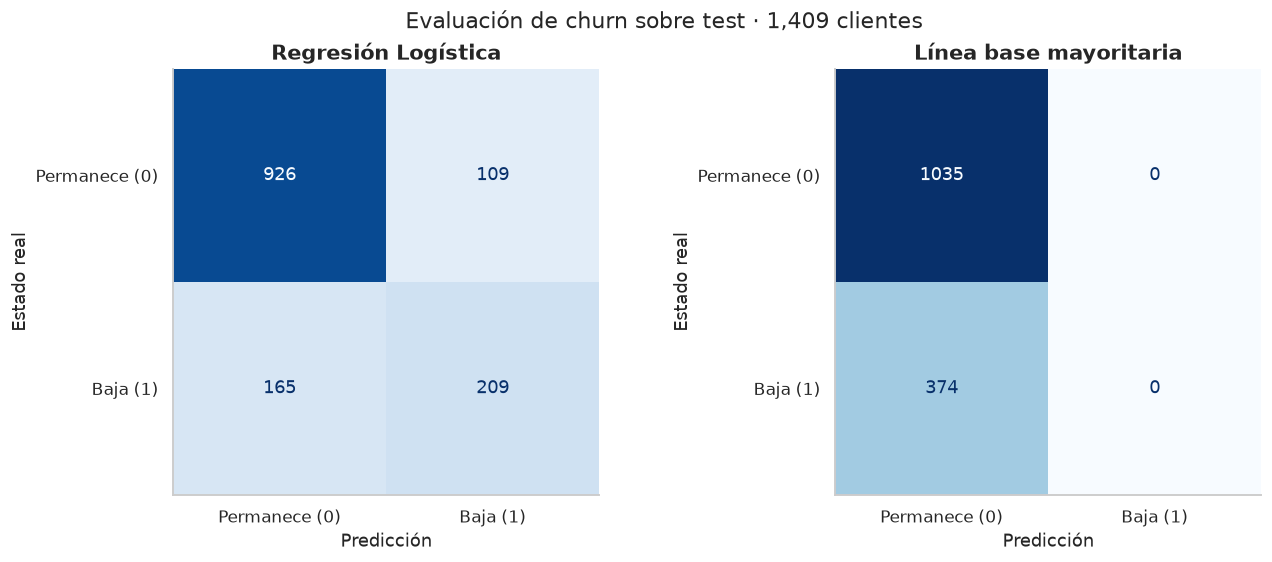

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
for ax, valores, titulo in zip(axes, [matriz, matriz_base],
                              ['Regresión Logística', 'Línea base mayoritaria']):
    disp = ConfusionMatrixDisplay(valores, display_labels=['Permanece (0)', 'Baja (1)'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d',
              im_kw={'vmin': 0, 'vmax': max(matriz.max(), matriz_base.max())})
    ax.set_title(titulo)
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Estado real')
    ax.grid(False)
fig.suptitle(f'Evaluación de churn sobre test · {len(y_test):,} clientes')
ruta_figura = guardar_figura(fig, '27_matrices_confusion')
plt.show()
plt.close(fig)
print(f'Figura: {ruta_figura.relative_to(RAIZ).as_posix()}')


### 4. Errores y decisiones de negocio

Un **falso negativo** es un cliente que se va pero al que el modelo clasifica como permanencia: puede quedar fuera de una campaña de retención. Un **falso positivo** es un cliente que permanece pero recibe una alerta: puede consumir presupuesto de contacto o incentivos innecesarios. Calculamos también recall y precisión de la clase baja para describir estos errores; no reemplazan la exactitud solicitada.

In [73]:
recall = tp / (tp + fn)
precision = tp / (tp + fp) if tp + fp else 0.0
print(f'Verdaderos negativos: {tn}; falsos positivos: {fp}.')
print(f'Falsos negativos: {fn}; verdaderos positivos: {tp}.')
print(f'Bajas detectadas: {tp} de {tp + fn} ({recall:.1%}).')
print(f'Bajas omitidas: {fn} de {tp + fn} ({1 - recall:.1%}).')
print(f'Alertas que corresponden a bajas: {tp} de {tp + fp} ({precision:.1%}).')


Verdaderos negativos: 926; falsos positivos: 109.
Falsos negativos: 165; verdaderos positivos: 209.
Bajas detectadas: 209 de 374 (55.9%).
Bajas omitidas: 165 de 374 (44.1%).
Alertas que corresponden a bajas: 209 de 318 (65.7%).


#### Interpretación y cierre

La Regresión Logística acierta **1.135 de 1.409 clientes (80,55 %)**, frente a **1.035 (73,46 %)** de la línea base: mejora **7,10 puntos porcentuales**, equivalentes a 100 aciertos adicionales. La línea base predice siempre permanencia y omite las 374 bajas.

La matriz del modelo muestra **926 verdaderos negativos, 109 falsos positivos, 165 falsos negativos y 209 verdaderos positivos**. Detecta el **55,9 %** de las bajas y omite el **44,1 %** restante. De las 318 alertas, **65,7 %** corresponden a bajas reales. Por eso, una exactitud de 80,55 % no significa que se detecte ese porcentaje de clientes que se van.

- **165 falsos negativos:** clientes que abandonan sin ser señalados; representan oportunidades perdidas de contacto preventivo.
- **109 falsos positivos:** clientes que permanecen pero serían contactados; implican esfuerzo comercial y posibles descuentos innecesarios.

No asignamos costos monetarios porque el dataset no incluye el costo de contactar, el incentivo ni el valor perdido por abandono. Tampoco permite afirmar que una campaña hubiera evitado las bajas: eso requiere medir su efecto. Si perder un cliente cuesta más que contactarlo, convendría estudiar mayor sensibilidad, evaluando umbrales mediante validación dentro de train y considerando el presupuesto. El test ya utilizado se reserva como resultado de esta evaluación; no se usa para ajustar el modelo.

Se cumple el criterio de la tarea: exactitud y línea base calculadas sobre test, matrices graficadas y errores interpretados. El resultado describe esta partición y no garantiza el mismo rendimiento en clientes futuros. La revisión cruzada corresponde a Emmanuel según el plan; el PR debe revisarse antes de integrarse.

## Tarea 28 · Interpretación de los coeficientes del modelo

Origen — `28_interpretacion_coeficientes.ipynb`.

### 1. Estilo común del TPI

Celda definida en la tarea 16 (paleta, tamaños y la función `guardar_figura`).

### 2. Carga de datos y reconstrucción del modelo

Leemos los datos de entrenamiento y los coeficientes de la tarea 26. Reentrenamos el modelo con la misma configuración (`max_iter=1000`, `random_state=42`) y comprobamos que coincide con los coeficientes guardados.

In [74]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression

GITHUB_REPO = 'julianschmidt1/tpi-analisis-de-datos'
GITHUB_REF = 'main'
RUTAS = {
    'x': Path('data/processed/X_train.csv'),
    'y': Path('data/processed/y_train.csv'),
    'coef': Path('data/processed/26_coeficientes_logistica.csv'),
}

def fuente(ruta):
    if EN_COLAB:
        return f'https://raw.githubusercontent.com/{GITHUB_REPO}/{GITHUB_REF}/{ruta.as_posix()}'
    return RAIZ / ruta

X_train = pd.read_csv(fuente(RUTAS['x']), index_col='fila_origen')
y_train = pd.read_csv(fuente(RUTAS['y']), index_col='fila_origen')['Churn']
coef_guardados = pd.read_csv(fuente(RUTAS['coef'])).set_index('variable')

modelo = LogisticRegression(max_iter=1000, random_state=42).fit(X_train, y_train)

assert X_train.index.equals(y_train.index)
assert np.allclose(coef_guardados.loc[X_train.columns, 'coeficiente'].to_numpy(), modelo.coef_[0]), \
    'El modelo reentrenado no coincide con la tarea 26.'

print(f'Clientes de entrenamiento: {len(X_train):,} · Variables: {X_train.shape[1]}')
print('El modelo reentrenado coincide con los coeficientes de la tarea 26.')
print(f'Probabilidad media de baja predicha (base): {modelo.predict_proba(X_train)[:, 1].mean():.1%}')

Clientes de entrenamiento: 5,634 · Variables: 46
El modelo reentrenado coincide con los coeficientes de la tarea 26.
Probabilidad media de baja predicha (base): 26.5%


### 3. Primera lectura: los coeficientes de mayor peso

Mostramos los 10 coeficientes más grandes en valor absoluto. Las variables numéricas están estandarizadas, así que su coeficiente se lee "por cada desvío estándar de aumento".

In [75]:
coeficientes = coef_guardados.copy()
coeficientes['coeficiente'] = coeficientes['coeficiente'].round(3)
coeficientes['odds_ratio'] = coeficientes['odds_ratio'].round(3)
coeficientes.head(10)

Out[75]: 
                                             coeficiente  odds_ratio
variable                                                            
numericas__tenure                                 -1.243       0.289
contrato__Contract                                -0.689       0.502
nominal__InternetService_Fiber optic               0.667       1.948
nominal__InternetService_DSL                      -0.616       0.540
numericas__MonthlyCharges                         -0.586       0.557
nominal__PaperlessBilling_No                      -0.294       0.745
nominal__OnlineBackup_No internet service         -0.266       0.766
nominal__OnlineSecurity_No internet service       -0.266       0.766
nominal__InternetService_No                       -0.266       0.766
nominal__TechSupport_No internet service          -0.266       0.766


### 4. Antes de interpretar: dos advertencias

Si leyéramos esta tabla al pie de la letra, sacaríamos conclusiones equivocadas. Hay dos problemas.

#### 4.1 Columnas repetidas

Varias filas de la tabla tienen **exactamente el mismo coeficiente (−0,266)**. Mostramos cuáles son.

In [76]:
repetidas = coef_guardados['coeficiente'].round(3).value_counts()
valor_repetido = repetidas.index[0]
columnas_repetidas = coef_guardados.index[coef_guardados['coeficiente'].round(3) == valor_repetido].tolist()
print(f'Columnas con coeficiente {valor_repetido}: {len(columnas_repetidas)}')
for columna in columnas_repetidas:
    print(' -', columna)
print()
print('¿Son la misma información?', X_train[columnas_repetidas].nunique().eq(2).all() and
      X_train[columnas_repetidas].T.drop_duplicates().shape[0] == 1)

Columnas con coeficiente -0.266: 7
 - nominal__OnlineBackup_No internet service
 - nominal__OnlineSecurity_No internet service
 - nominal__InternetService_No
 - nominal__TechSupport_No internet service
 - nominal__StreamingMovies_No internet service
 - nominal__DeviceProtection_No internet service
 - nominal__StreamingTV_No internet service

¿Son la misma información? True


Las siete columnas son **la misma información** repetida: "el cliente no tiene internet" (`InternetService = No`) aparece una vez por cada servicio asociado (seguridad, backup, protección, soporte, TV, películas). El modelo reparte el efecto entre las siete. Por eso **ninguna se debe leer por separado**: el efecto real de "no tener internet" es la **suma** de las siete.

#### 4.2 Variables numéricas muy relacionadas

`TotalCharges`, `ingreso_estimado` (= `MonthlyCharges × tenure`) y `tenure` están muy relacionadas. El **VIF** mide cuánto se puede reconstruir una variable a partir de las demás: un valor mayor que 10 es una señal de alerta, e infinito significa que es una combinación exacta de las otras.

In [77]:
numericas = [c for c in X_train.columns if c.startswith('numericas__')]
filas = []
for columna in numericas:
    otras = [c for c in numericas if c != columna]
    r2 = LinearRegression().fit(X_train[otras], X_train[columna]).score(X_train[otras], X_train[columna])
    filas.append({'variable': columna.replace('numericas__', ''), 'R2': round(r2, 4),
                  'VIF': 'infinito' if r2 > 0.99999 else round(1 / (1 - r2), 1)})
display(pd.DataFrame(filas).set_index('variable'))

print('Correlación entre variables numéricas (entrenamiento):')
X_train[numericas].rename(columns=lambda c: c.replace('numericas__', '')).corr().round(2)

Correlación entre variables numéricas (entrenamiento):
Out[77]: 
                        tenure  ...  diferencia_facturacion
tenure                    1.00  ...                    0.01
MonthlyCharges            0.26  ...                   -0.00
TotalCharges              0.83  ...                    0.04
ingreso_estimado          0.83  ...                    0.01
diferencia_facturacion    0.01  ...                    1.00

[5 rows x 5 columns]


,R2,VIF
variable,,
tenure,0.8325,6.0
MonthlyCharges,0.6923,3.3
TotalCharges,1.0000,infinito
ingreso_estimado,1.0000,infinito
diferencia_facturacion,1.0000,infinito


`TotalCharges` e `ingreso_estimado` tienen correlación 1,00 y `diferencia_facturacion` es exactamente su resta, de modo que las tres son una combinación exacta entre sí (VIF infinito). `tenure` y `MonthlyCharges` también quedan relacionadas con ellas (VIF de 6,0 y 3,3). **Consecuencia:** los coeficientes de las variables de facturación no son confiables de forma individual.

### 5. Comprobación de robustez

Probamos qué pasa si quitamos las dos columnas calculadas (`ingreso_estimado` y `diferencia_facturacion`) y reentrenamos. Si una conclusión es sólida, no debería cambiar. Todo se hace con datos de entrenamiento.

In [78]:
sin_calculadas = X_train.drop(columns=['numericas__ingreso_estimado', 'numericas__diferencia_facturacion'])
modelo_reducido = LogisticRegression(max_iter=1000, random_state=42).fit(sin_calculadas, y_train)
coef_reducido = pd.Series(modelo_reducido.coef_[0], index=sin_calculadas.columns)
coef_completo = pd.Series(modelo.coef_[0], index=X_train.columns)

variables_clave = [
    'numericas__tenure', 'contrato__Contract', 'nominal__InternetService_Fiber optic',
    'nominal__InternetService_DSL', 'nominal__PaperlessBilling_Yes',
    'numericas__MonthlyCharges', 'numericas__TotalCharges',
]
robustez = pd.DataFrame({
    'con todas las variables': coef_completo[variables_clave],
    'sin columnas calculadas': coef_reducido[variables_clave],
}).round(3)
display(robustez)
print(f'Accuracy en entrenamiento: {modelo.score(X_train, y_train):.1%} (completo) · '
      f'{modelo_reducido.score(sin_calculadas, y_train):.1%} (sin columnas calculadas)')

Accuracy en entrenamiento: 80.6% (completo) · 80.6% (sin columnas calculadas)


,con todas las variables,sin columnas calculadas
numericas__tenure,-1.243,-1.250
contrato__Contract,-0.689,-0.693
nominal__InternetService_Fiber optic,0.667,0.672
nominal__InternetService_DSL,-0.616,-0.620
nominal__PaperlessBilling_Yes,0.078,0.078
numericas__MonthlyCharges,-0.586,-0.598
numericas__TotalCharges,0.259,0.528


**Lectura:**

- `tenure`, `Contract`, fibra óptica y DSL **casi no cambian** al quitar las columnas calculadas. Son conclusiones **sólidas**.
- `TotalCharges` **sí cambia mucho** (de 0,26 a 0,53): su coeficiente depende de qué otras variables acompañen al modelo. **No se debe interpretar**.
- `MonthlyCharges` mantiene signo negativo en ambos casos aunque quienes se van pagan más (gráficos de la tarea 17). Es un efecto de "con lo demás igual": una vez que el modelo ya sabe qué servicio tiene el cliente (por ejemplo, fibra óptica, que es cara), el cargo extra no agrega información por sí mismo. El cargo alto se refleja a través del tipo de servicio.
- El rendimiento sobre entrenamiento es prácticamente igual (80,6 %): las columnas calculadas no aportan al modelo.

### 6. Efecto de cada variable en la probabilidad de baja

Los coeficientes y odds ratios son difíciles de comunicar. Una forma más clara: **¿cuánto cambia la probabilidad de baja si todos los clientes pertenecieran a una categoría u otra?** Para cada variable, fijamos esa característica en todos los clientes de entrenamiento, dejando todo lo demás como está, y calculamos la probabilidad media de baja que predice el modelo. Esto resuelve el problema de las columnas repetidas, porque se cambia el conjunto completo de columnas de cada variable a la vez.

Es una simulación del modelo, no un experimento: muestra qué asocia el modelo con cada característica, no qué pasaría si la empresa cambiara a los clientes de categoría.

In [79]:
def probabilidad_media(cambios):
    escenario = X_train.copy()
    for columna, valor in cambios.items():
        escenario[columna] = valor
    return modelo.predict_proba(escenario)[:, 1].mean()

def fijar_categoria(prefijo, categoria):
    cambios = {c: 0.0 for c in X_train.columns if c.startswith(prefijo)}
    cambios[prefijo + categoria] = 1.0
    return cambios

base = modelo.predict_proba(X_train)[:, 1].mean()
desvio = 1.0  # tenure ya está estandarizado: 1 unidad = 1 desvío estándar (≈ 25 meses)

escenarios = [
    ('Antigüedad', '1 desvío menos (cliente más nuevo)', {'numericas__tenure': X_train['numericas__tenure'] - desvio}),
    ('Antigüedad', 'Antigüedad actual', {}),
    ('Antigüedad', '1 desvío más (cliente más antiguo)', {'numericas__tenure': X_train['numericas__tenure'] + desvio}),
    ('Contrato', 'Mensual', {'contrato__Contract': 0.0}),
    ('Contrato', 'Un año', {'contrato__Contract': 1.0}),
    ('Contrato', 'Dos años', {'contrato__Contract': 2.0}),
    ('Internet', 'DSL', fijar_categoria('nominal__InternetService_', 'DSL')),
    ('Internet', 'Fibra óptica', fijar_categoria('nominal__InternetService_', 'Fiber optic')),
    ('Pago', 'Cheque electrónico', fijar_categoria('nominal__PaymentMethod_', 'Electronic check')),
    ('Pago', 'Cheque por correo', fijar_categoria('nominal__PaymentMethod_', 'Mailed check')),
    ('Pago', 'Transferencia automática', fijar_categoria('nominal__PaymentMethod_', 'Bank transfer (automatic)')),
    ('Pago', 'Tarjeta automática', fijar_categoria('nominal__PaymentMethod_', 'Credit card (automatic)')),
    ('Factura electrónica', 'Sí', fijar_categoria('nominal__PaperlessBilling_', 'Yes')),
    ('Factura electrónica', 'No', fijar_categoria('nominal__PaperlessBilling_', 'No')),
]
efectos = pd.DataFrame(
    [{'variable': v, 'escenario': e, 'prob_baja': probabilidad_media(c)} for v, e, c in escenarios]
)
efectos['diferencia_vs_base_pp'] = (efectos['prob_baja'] - base) * 100

print(f'Probabilidad media de baja con los clientes tal como están: {base:.1%}')
mostrar = efectos.copy()
mostrar['prob_baja'] = (mostrar['prob_baja'] * 100).round(1).astype(str) + ' %'
mostrar['diferencia_vs_base_pp'] = mostrar['diferencia_vs_base_pp'].round(1)
mostrar.set_index(['variable', 'escenario'])

Probabilidad media de baja con los clientes tal como están: 26.5%
Out[79]: 
                                                       prob_baja  diferencia_vs_base_pp
variable            escenario                                                          
Antigüedad          1 desvío menos (cliente más nuevo)    44.7 %                   18.2
                    Antigüedad actual                     26.5 %                    0.0
                    1 desvío más (cliente más antiguo)    12.4 %                  -14.1
Contrato            Mensual                               29.8 %                    3.2
                    Un año                                19.9 %                   -6.6
                    Dos años                              12.4 %                  -14.2
Internet            DSL                                   16.7 %                   -9.9
                    Fibra óptica                          34.4 %                    7.9
Pago                Cheque electrónico      

Figura exportada: reports/figures/28_efecto_variables.png


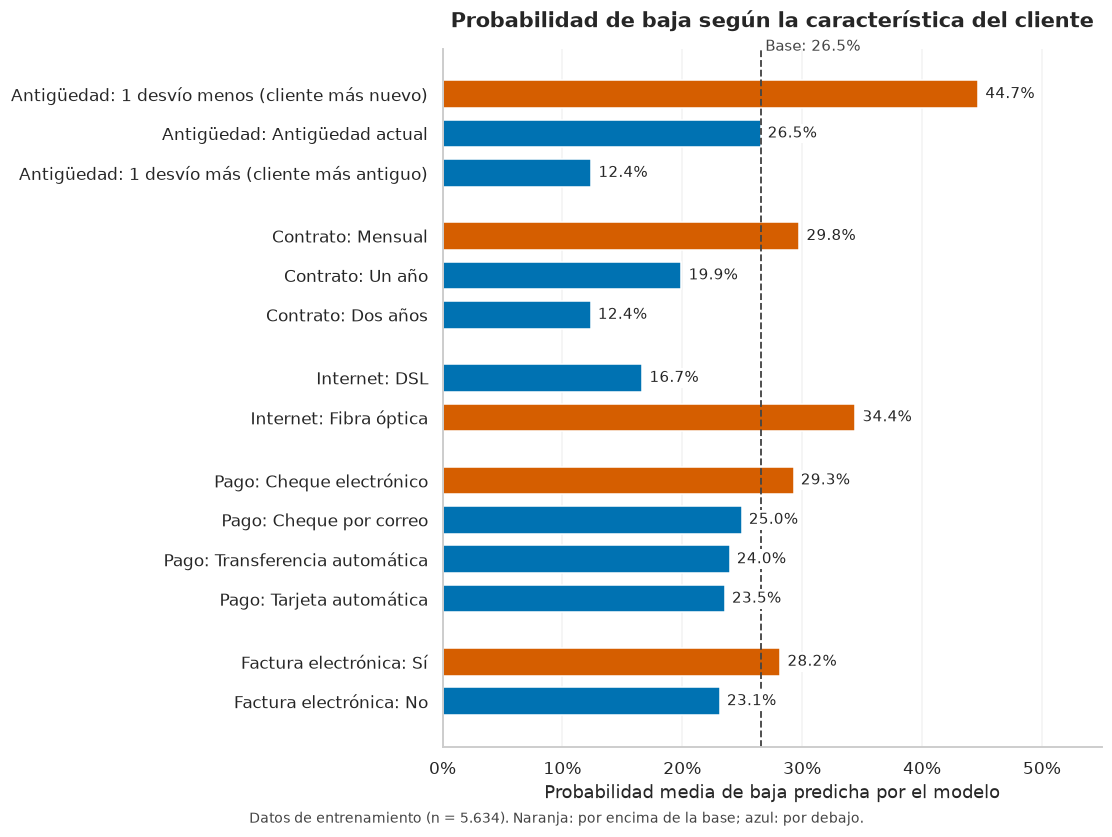

In [80]:
fig, ax = plt.subplots(figsize=(10, 7.5), layout='constrained')

posiciones, etiquetas, y_actual = [], [], 0
for variable, grupo in efectos.groupby('variable', sort=False):
    for _, fila in grupo.iterrows():
        color = COLORES_CHURN['Yes'] if fila['prob_baja'] > base else COLORES_CHURN['No']
        ax.barh(y_actual, fila['prob_baja'], color=color, height=0.7)
        ax.text(fila['prob_baja'] + 0.006, y_actual, f"{fila['prob_baja']:.1%}", va='center', fontsize=10,
                bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5}, zorder=5)
        posiciones.append(y_actual)
        etiquetas.append(f"{variable}: {fila['escenario']}")
        y_actual += 1
    y_actual += 0.6  # espacio entre variables

ax.axvline(base, color='#444444', linestyle='--', linewidth=1.2, zorder=1)
ax.text(base + 0.004, -1.1, f'Base: {base:.1%}', fontsize=10, color='#444444')
ax.set_yticks(posiciones)
ax.set_yticklabels(etiquetas)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set_xlim(0, 0.55)
ax.set_xlabel('Probabilidad media de baja predicha por el modelo')
ax.set_title('Probabilidad de baja según la característica del cliente', pad=14)
ax.yaxis.grid(False)
fig.supxlabel('Datos de entrenamiento (n = 5.634). Naranja: por encima de la base; azul: por debajo.',
              fontsize=9, color='#444444')

ruta = guardar_figura(fig, '28_efecto_variables')
plt.show()
plt.close(fig)
print(f'Figura exportada: {ruta.relative_to(RAIZ).as_posix()}')

### 7. Variables destacadas y su lectura de negocio

Estas son las cinco variables con efecto más claro. Las tres primeras son **sólidas** (no cambian al quitar columnas calculadas); las dos últimas son efectos **más modestos**.

1. **Antigüedad (`tenure`): el factor más fuerte.** Con un desvío estándar (≈ 25 meses) menos de antigüedad, la probabilidad de baja sube a 44,7 %; con uno más, baja a 12,4 %. *Lectura de negocio:* el riesgo se concentra en los primeros meses. Es consistente con los histogramas de la tarea 17. Conviene reforzar la retención en clientes nuevos (bienvenida, seguimiento, ofertas tempranas).
2. **Tipo de contrato: la permanencia se premia con estabilidad.** Si todos tuvieran contrato mensual, la probabilidad sería 29,8 %; con contrato de un año, 19,9 %, y de dos años, 12,4 %. *Lectura de negocio:* los contratos largos van asociados a menos bajas. Una acción posible es ofrecer incentivos para migrar clientes del plan mensual a uno anual.
3. **Internet de fibra óptica: el servicio con más riesgo.** Con DSL la probabilidad es 16,7 % y con fibra, 34,4 %: casi 18 puntos porcentuales de diferencia. *Lectura de negocio:* la fibra, que es el servicio más caro, concentra bajas. Convendría revisar su relación calidad-precio y si el cliente percibe el valor. Esto coincide con el hallazgo 3 del análisis exploratorio.
4. **Cheque electrónico como método de pago.** Con cheque electrónico la probabilidad es 29,3 %, frente a 23,5 % con tarjeta automática y 24,0 % con transferencia automática (unos 6 puntos más). *Lectura de negocio:* los pagos automáticos se asocian a menos bajas. Podría incentivarse el débito automático. El efecto es más modesto que los anteriores.
5. **Factura electrónica (`PaperlessBilling`).** Con factura electrónica la probabilidad es 28,2 % y sin ella, 23,1 % (5 puntos más). *Lectura de negocio:* un efecto moderado; sirve como señal de riesgo complementaria, no como causa.

**Variables que no se deben interpretar individualmente:** `MonthlyCharges`, `TotalCharges`, `ingreso_estimado` y `diferencia_facturacion`, por colinealidad (sección 4.2), y los coeficientes de cada servicio "No internet service", por columnas repetidas (sección 4.1).

### 8. Límites de esta interpretación

- **Asociación, no causalidad.** El modelo describe qué características acompañan a las bajas. No demuestra que cambiar el contrato de un cliente evite que se vaya.
- **Datos de entrenamiento.** Los porcentajes salen de simular el modelo sobre los clientes de entrenamiento; no son una medición sobre clientes nuevos.
- **El modelo es imperfecto.** En test detecta cerca del 56 % de las bajas (tarea 27). Las conclusiones valen como pistas de dónde mirar, no como regla exacta.

### 9. Resultado de la tarea

Se interpretó el modelo con cuidado: se detectaron las columnas repetidas y la colinealidad que hacen engañosa la lectura directa de los coeficientes, se verificó la robustez quitando las columnas calculadas y se tradujo el efecto de cada variable a probabilidad de baja. Las variables más relevantes son la **antigüedad**, el **contrato** y la **fibra óptica**, seguidas por el **método de pago** y la **factura electrónica**. La figura `reports/figures/28_efecto_variables.png` queda disponible para el informe.